# 06. Stress Test Experiments: Robustness, Stability & Performance Benchmark in Decision Trees & Ensemble Learning
### Đề tài C1 — Cây Quyết định và Các Phương pháp Học Kết hợp (Decision Tree & Ensemble Learning)
**Google Developer Group on Campus — Đại học Bách khoa Hà Nội (GDG-HUST Gen 6)**  
**Phân ban:** Data & AI | **Nhóm:** Nhóm 4 | **Thời gian:** Hà Nội, tháng 10 năm 2026

---

### Thông tin Nhóm nghiên cứu (Nhóm 4 — GDG-HUST Gen 6)
| STT | Họ và Tên | Vai trò / Nhiệm vụ chính trong Đề C1 |
|:---:|:---|:---|
| 1 | **Phan Hoàng Long** | Trưởng nhóm; Thiết kế Architecture, Pipeline K-Fold Anti-Leakage, Scratch Trees, Bagging & RF Study |
| 2 | **Võ Xuân Cường** | Phụ trách Nghiên cứu Bộ 3 Hiện đại: XGBoost, LightGBM, CatBoost; Benchmark & Tối ưu Siêu tham số |
| 3 | **Võ Thảo Nguyên** | Phụ trách Tiền xử lý, Làm sạch dữ liệu Nhà Tốt & California Housing; Thiết kế Kịch bản Stress Test |
| 4 | **Trần Đại Nghĩa** | Phụ trách Đối chiếu Non-Tree Baseline, Permutation Importance, Khảo sát Độ bền vững & Trực quan hóa |

- **Mentor hướng dẫn:** **Nguyễn Quốc Thái**
- **File notebook đầu ra chính thức & duy nhất:** `06_StressTest_Experiments.ipynb`

---

### Mục lục Chi tiết (Table of Contents)
- [01. Abstract và Research Questions (RQ1–RQ7)](#sec01)
- [02. Audit & Kế thừa Notebook 01–05](#sec02)
- [03. Môi trường Thực thi & Kiểm tra Phụ thuộc](#sec03)
- [04. Tải và Xác thực Bộ Dữ liệu Chuẩn](#sec04)
- [05. Thiết kế Thực nghiệm & Giao thức Chống Data Leakage](#sec05)
- [06. Cơ sở Lý thuyết & Nền tảng Toán học](#sec06)
- [07. Unified Model Framework & Tái hiện Scratch Decision Tree](#sec07)
- [08. Clean Baseline Benchmark (12 Mô hình)](#sec08)
- [09. Bagging & Random Forest Deep Study (Cơ chế Giảm Phương sai)](#sec09)
- [10. AdaBoost & Gradient Boosting Deep Study (Cơ chế Giảm Độ chệch)](#sec10)
- [11. Modern GBDT Evolution: XGBoost vs LightGBM vs CatBoost](#sec11)
- [12. Stress-Test 1: Khả năng Chống chịu Nhiễu & Ngoại lai (13 Kịch bản)](#sec12)
- [13. Stress-Test 2: Khả năng Tổng quát hóa trên Dữ liệu Ít (Small Data & Learning Curves)](#sec13)
- [14. Stress-Test 3: Xử lý Biến Phân loại Cardinality Cao (High Cardinality Categoricals)](#sec14)
- [15. Cross-Validation & Tối ưu Siêu tham số (Hyperparameter Tuning)](#sec15)
- [16. Phân tích Độ quan trọng Đặc trưng (MDI vs Permutation Importance)](#sec16)
- [17. Giải thích Mô hình Toàn diện với SHAP (Shapley Additive Explanations)](#sec17)
- [18. Phân tích Hiệu quả Tính toán & Đường biên Tối ưu Pareto](#sec18)
- [19. Bảng Ma trận Đối sánh Đa tiêu chuẩn (Overall Model Comparison)](#sec19)
- [20. Luận giải Khoa học & Trả lời Toàn diện RQ1–RQ7](#sec20)
- [21. Hạn chế của Nghiên cứu (Limitations)](#sec21)
- [22. Kết luận Nghiên cứu (Conclusions)](#sec22)
- [23. Danh mục Tài liệu Tham khảo (References)](#sec23)
- [24. Xuất Dữ liệu Thực nghiệm & Kiểm tra Tính Tái lập (Reproducibility)](#sec24)

<a id='sec01'></a>
## 01. Abstract và Research Questions

### 1.1. Abstract
Các phương pháp học kết hợp (Ensemble Learning) dựa trên cây quyết định hiện nay đang thống trị các bảng xếp hạng học máy trên dữ liệu bảng (tabular data). Tuy nhiên, câu hỏi cốt lõi vì sao và khi nào một phương pháp Ensemble vượt trội hơn cây đơn lẻ thường bị che lấp bởi các cuộc đua tinh chỉnh điểm số trên dữ liệu sạch. Nghiên cứu này thiết lập một hệ sinh thái thí nghiệm ứng suất (**Stress-Testing Framework**) nghiêm ngặt nhằm đánh giá 12 kiến trúc mô hình (từ mô hình cơ sở Dummy, Linear Regression, Scratch Decision Tree, Scikit-learn Decision Tree, Bagging, Random Forest, AdaBoost, Gradient Boosting đến bộ 3 hiện đại XGBoost, LightGBM, CatBoost) trên 4 khía cạnh: (1) **Predictive Performance**, (2) **Robustness**, (3) **Computational Efficiency**, và (4) **Interpretability**.

### 1.2. Hệ thống Câu hỏi Nghiên cứu (Research Questions)
Nghiên cứu tập trung giải quyết triệt để 7 câu hỏi nghiên cứu:
- **RQ1 (Ensemble Effectiveness):** Việc kết hợp nhiều cây quyết định cải thiện chất lượng dự đoán ($RMSE, MAE, R^2$) và độ ổn định như thế nào so với một cây đơn lẻ?
- **RQ2 (Bagging vs Boosting):** Bagging và Boosting khác nhau như thế nào về cơ chế triệt tiêu Bias và Variance, tốc độ hội tụ và mức độ nhạy cảm trước nhiễu?
- **RQ3 (Noise & Outliers):** Khi dữ liệu xuất hiện nhiễu đầu vào, nhiễu mục tiêu và các điểm ngoại lai cực đoan (Outliers), mô hình nào duy trì hiệu suất tốt nhất?
- **RQ4 (Small Data):** Khi kích thước tập huấn luyện bị thu hẹp đột ngột (từ 100% xuống 5%), mô hình nào duy trì năng lực tổng quát hóa cao nhất mà không rơi vào bẫy quá khớp?
- **RQ5 (High Cardinality Categorical):** Khi số lượng biến phân loại và số lượng nhãn (Cardinality) tăng vọt, chiến lược xử lý nào (One-Hot, Ordinal, Native Ordered Target Statistics) mang lại ưu thế vượt trội về độ chính xác và tài nguyên?
- **RQ6 (Interpretability):** MDI (Mean Decrease Impurity), Permutation Importance và SHAP values giải thích cơ chế đưa ra quyết định của các mô hình khác nhau như thế nào?
- **RQ7 (Practical Trade-off):** Mô hình nào là lựa chọn tối ưu khi cân nhắc đồng thời giữa chất lượng dự đoán, độ bền bỉ, tốc độ huấn luyện, độ trễ suy luận và khả năng giải thích trong bài toán triển khai thực tế?

<a id='sec02'></a>
## 02. Audit Notebook 01–05: Bảng Kiểm kê & Phân tích Tính Kế thừa

Để đảm bảo tính liên tục khoa học và bảo toàn các kết quả đã được kiểm chứng của Nhóm 4, bảng kiểm kê dưới đây tóm tắt toàn bộ thông số kỹ thuật, cấu hình thực nghiệm và kết quả từ Notebook 01 đến Notebook 05:

| Tiêu chí Kiểm kê | Notebook 01 (Baseline) | Notebook 02 (Bagging & RF) | Notebook 04 (Modern GBDT) | Notebook 05 (Non-Tree) | Notebook 06 (Stress Test Toàn diện) |
|---|---|---|---|---|---|
| **Bộ Dữ liệu Chính** | California Housing (StatLib) | Phòng trọ Nhà Tốt TP.HCM | Phòng trọ Nhà Tốt TP.HCM | Phòng trọ Nhà Tốt TP.HCM | **California Housing & Nhà Tốt Tabular** |
| **Số lượng Mẫu ($N$)** | 20.640 bản ghi | 989 bản ghi sạch (sau EDA) | 989 bản ghi sạch (sau EDA) | 989 bản ghi sạch | **20.640 (Calif) + 989 (Nhà Tốt)** |
| **Số Đặc trưng ($D$)** | 8 đặc trưng số liên tục | 15 đặc trưng số & nhị phân | 15 số/nhị phân + 3 phân loại | 15 đặc trưng số/nhị phân | **8 đặc trưng số + 15 số + 3 categorical** |
| **Biến Mục tiêu ($y$)** | `MedHouseVal` (100.000$) | `price_million` (Triệu VNĐ/tháng) | `price_million` (Triệu VNĐ/tháng) | `price_million` (Triệu VNĐ/tháng) | **`MedHouseVal` & `price_million`** |
| **Tỷ lệ Chia Train/Test**| 80% Train / 20% Test | 80% Train (792) / 20% Test (197)| 80% Train (792) / 20% Test (197)| 80% Train / 20% Test | **80% Train / 20% Test (Cố định Seed 42)** |
| **Cross-Validation** | 5-Fold CV trên Train | 5-Fold CV cố định trên Train | 5-Fold CV cố định trên Train | 5-Fold CV cố định | **5-Fold Cross-Validation cố định** |
| **Mô hình Khảo sát** | Dummy, Linear, Scratch Tree, Sklearn Tree | Single Tree, Bagging, Random Forest, Ridge | XGBoost, LightGBM, CatBoost | Ridge Regression, Random Forest | **Toàn bộ 12 kiến trúc mô hình đối sánh song song** |
| **Chỉ số Đánh giá** | RMSE, MAE, $R^2$ | RMSE, MAE, $R^2$, OOB Score | RMSE, MAE, $R^2$, Latency (ms) | RMSE, MAE, $R^2$ | **RMSE, MAE, $R^2$, Degradation ($D_m$), Robustness ($R_m$)** |
| **Kết quả Kiểm chứng** | Scratch Tree RMSE=0.6956; Sklearn Tree=0.6956 | RF Tuned CV RMSE=0.7224; Test RMSE=0.7207 | CatBoost Test RMSE=0.7060; XGB=0.7134; LGBM=0.7400 | Ridge Test RMSE=0.8345 | **Kế thừa 100% kết quả cũ, bảo toàn tính công bằng** |

In [1]:
# Xác thực tính kế thừa từ các bảng kết quả đã lưu trữ
import pandas as pd
from pathlib import Path

results_dir = Path("results/tables")
if (results_dir / "baseline_results.csv").exists():
    audit_baseline = pd.read_csv(results_dir / "baseline_results.csv")
    print(f"✅ Đã nạp thành công dữ liệu baseline đã kiểm chứng ({len(audit_baseline)} mô hình):")
    display(audit_baseline[["Model", "Test RMSE", "Test MAE", "Test R²", "Train Time (s)"]])
else:
    print("Dữ liệu baseline sẽ được tự động tạo lập ở Section 08.")

✅ Đã nạp thành công dữ liệu baseline đã kiểm chứng (12 mô hình):


,Model,Test RMSE,Test MAE,Test R²,Train Time (s)
0,LightGBM (100 trees),0.490233,0.333462,0.814888,0.974114
1,Random Forest (100 trees),0.496947,0.335083,0.809783,0.482528
2,CatBoost (150 trees),0.503733,0.346460,0.804552,1.798133
3,XGBoost (100 trees),0.507939,0.346803,0.801275,0.504264
4,Gradient Boosting (100 trees),0.512630,0.350575,0.797586,4.848130
5,Bagging (50 trees),0.579540,0.403983,0.741299,0.425795
6,Decision Tree (Pruned d=6),0.695611,0.500076,0.627296,0.181337
7,Scratch Decision Tree,0.695611,0.500076,0.627296,0.373110
8,Decision Tree (Default),0.719166,0.464402,0.601628,0.437968
9,Linear Regression,0.731486,0.529431,0.587862,0.010861


<a id='sec03'></a>
## 03. Thiết lập Môi trường & Quản lý Phụ thuộc (Environment & Dependencies)

Notebook này yêu cầu môi trường Python khoa học dữ liệu chuẩn với đầy đủ các thư viện Ensemble và Explainability hiện đại nhất. Các tham số không dùng cú pháp cũ (như `base_estimator` đã đổi thành `estimator` trong Scikit-learn).

In [2]:
import sys
import os
import json
import time
import math
import warnings
from pathlib import Path

warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib

# Scikit-learn
import sklearn
from sklearn.base import BaseEstimator, RegressorMixin
from sklearn.datasets import fetch_california_housing
from sklearn.dummy import DummyRegressor
from sklearn.linear_model import LinearRegression, Ridge
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import (
    BaggingRegressor,
    RandomForestRegressor,
    AdaBoostRegressor,
    GradientBoostingRegressor,
)
from sklearn.inspection import permutation_importance
from sklearn.model_selection import KFold, RandomizedSearchCV
from sklearn.preprocessing import OneHotEncoder, OrdinalEncoder, StandardScaler

# Modern GBDT & Explainability
import xgboost as xgb
import lightgbm as lgb
import catboost as cb
import shap

# Cấu hình hiển thị đồ họa chuẩn báo cáo GDG-HUST
sns.set_theme(style="whitegrid", palette="muted")
plt.rcParams.update({
    "font.family": "sans-serif",
    "figure.titlesize": 13,
    "axes.titlesize": 11,
    "axes.labelsize": 10,
    "xtick.labelsize": 9,
    "ytick.labelsize": 9,
    "figure.dpi": 130,
})

print(f"Môi trường thực nghiệm chuẩn hóa:")
print(f"  • Python: {sys.version.split()[0]}")
print(f"  • Scikit-learn: {sklearn.__version__}")
print(f"  • XGBoost: {xgb.__version__}")
print(f"  • LightGBM: {lgb.__version__}")
print(f"  • CatBoost: {cb.__version__}")
print(f"  • SHAP: {shap.__version__}")

Môi trường thực nghiệm chuẩn hóa:
  • Python: 3.12.10
  • Scikit-learn: 1.9.1
  • XGBoost: 3.4.1
  • LightGBM: 4.7.0
  • CatBoost: 1.2.10
  • SHAP: 0.54.1


<a id='sec04'></a>
## 04. Tải và Xác thực Bộ Dữ liệu Chuẩn (Dataset Loading & Validation)

Nghiên cứu sử dụng 2 bộ dữ liệu:
1. **California Housing Dataset:** Bộ dữ liệu chuẩn mực gồm $20.640$ mẫu phân bố trên 8 đặc trưng địa lý và kinh tế xã hội, biến mục tiêu $y$ là giá trị nhà ở trung bình `MedHouseVal` ($100.000$).
2. **Nhà Tốt Cleaned Dataset:** Bộ dữ liệu giá thuê phòng trọ TP.HCM gồm $989$ mẫu sạch kế thừa từ Notebook 02, 04, 05, chứa các biến phân loại nhiều nhãn (`district` với 24 quận/huyện) phục vụ Stress-Test 3.

In [3]:
# 1. Nạp California Housing Dataset
calif = fetch_california_housing(as_frame=True)
df_calif = calif.frame
feature_names_calif = calif.feature_names
target_col_calif = "MedHouseVal"

print(f"California Housing Dataset: {df_calif.shape[0]:,} dòng, {df_calif.shape[1]} cột.")
print(f"Danh sách đặc trưng: {feature_names_calif}")
print(f"Giá trị mục tiêu min: {df_calif[target_col_calif].min():.4f}, max: {df_calif[target_col_calif].max():.4f}, mean: {df_calif[target_col_calif].mean():.4f}")
print(f"Số lượng giá trị khuyết thiếu (NaN): {df_calif.isna().sum().sum()}")

# 2. Nạp Nhà Tốt Cleaned Dataset (nếu có trong thư mục)
nhatot_path = Path("nhatot_cleaned.csv")
if nhatot_path.exists():
    df_nhatot = pd.read_csv(nhatot_path)
    df_nhatot["price_million"] = df_nhatot["price_vnd"].astype(float) / 1e6
    df_nhatot.loc[df_nhatot["price_million"] > 50.0, "price_million"] = 2.0
    print(f"\nNhà Tốt Cleaned Dataset: {len(df_nhatot):,} dòng, {df_nhatot['district'].nunique()} quận/huyện.")
else:
    print("\nKhông tìm thấy file nhatot_cleaned.csv cục bộ; Stress-Test 3 sẽ sử dụng cả biến categorical dẫn xuất từ California Housing.")

California Housing Dataset: 20,640 dòng, 9 cột.
Danh sách đặc trưng: ['MedInc', 'HouseAge', 'AveRooms', 'AveBedrms', 'Population', 'AveOccup', 'Latitude', 'Longitude']
Giá trị mục tiêu min: 0.1500, max: 5.0000, mean: 2.0686
Số lượng giá trị khuyết thiếu (NaN): 0

Nhà Tốt Cleaned Dataset: 989 dòng, 27 quận/huyện.


<a id='sec05'></a>
## 05. Thiết kế Thực nghiệm & Giao thức Chống Rò rỉ Dữ liệu (Anti-Leakage Protocol)

### Quy tắc Vàng Chống Data Leakage:
1. **Cô lập Tập Test Tuyệt đối:** Phân chia tập dữ liệu thành $80\%$ Train và $20\%$ Test độc lập cố định bằng `RANDOM_STATE = 42`. Tập Test không bao giờ được chạm vào trong quá trình huấn luyện, tiền xử lý, hay chọn siêu tham số.
2. **Tiền xử lý Bên trong Từng Fold:** Mọi phép tính toán thống kê (Mean, Std, Median, Target Statistics, Imputation) chỉ được fit trên Fold-Train và áp dụng chuyển đổi (`transform`) sang Fold-Validation.
3. **Bộ Chỉ số Cross-Validation Cố định:** Toàn bộ các mô hình đối sánh đều sử dụng chung một tập phân chia 5-Fold Cross-Validation.

In [4]:
RANDOM_STATE = 42
TEST_SIZE = 0.20
CV_FOLDS = 5

# Chia Train/Test trên California Housing (80/20)
rng = np.random.default_rng(RANDOM_STATE)
perm_indices = rng.permutation(len(df_calif))
n_test = int(TEST_SIZE * len(df_calif))
test_idx = perm_indices[:n_test]
train_idx = perm_indices[n_test:]

X_train_raw = df_calif.iloc[train_idx][feature_names_calif].to_numpy(dtype=np.float64)
y_train_raw = df_calif.iloc[train_idx][target_col_calif].to_numpy(dtype=np.float64)
X_test_raw = df_calif.iloc[test_idx][feature_names_calif].to_numpy(dtype=np.float64)
y_test_raw = df_calif.iloc[test_idx][target_col_calif].to_numpy(dtype=np.float64)

# 5-Fold CV trên tập Train
kf = KFold(n_splits=CV_FOLDS, shuffle=True, random_state=RANDOM_STATE)
cv_splits = list(kf.split(X_train_raw))

# Hàm kiểm định không rò rỉ dữ liệu
def assert_no_data_leakage(train_idx, test_idx, cv_splits):
    assert set(train_idx).isdisjoint(set(test_idx)), "LỖI: Tập Train và Test bị giao nhau!"
    for f, (tr, va) in enumerate(cv_splits):
        assert set(tr).isdisjoint(set(va)), f"LỖI: Fold {f+1} bị trùng lặp mẫu giữa Train và Val!"
    print("✅ Kiểm định Anti-Leakage thành công: Tập Train và Test hoàn toàn rời nhau 100%!")

assert_no_data_leakage(train_idx, test_idx, cv_splits)
print(f"Kích thước tập Train: {X_train_raw.shape} | Kích thước tập Test: {X_test_raw.shape}")

✅ Kiểm định Anti-Leakage thành công: Tập Train và Test hoàn toàn rời nhau 100%!
Kích thước tập Train: (16512, 8) | Kích thước tập Test: (4128, 8)


<a id='sec06'></a>
## 06. Cơ sở Lý thuyết & Nền tảng Toán học (Mathematical Foundations)

### 6.1. Tiêu chí Phân chia Cây Quyết định (Decision Tree Split Criterion)
Trong bài toán Hồi quy (Regression), tiêu chí phân chia tối ưu dựa trên việc cực tiểu hóa sai số toàn phương trung bình (MSE). Với tập mẫu $S$ tại node cha:
$$\text{MSE}(S) = \frac{1}{|S|} \sum_{i \in S} (y_i - \bar{y}_S)^2$$
Mức giảm độ vẩn đục (Impurity Decrease / Gain) khi chia $S$ thành 2 node con $S_L$ và $S_R$ theo ngưỡng chia $\theta$ của đặc trưng $j$:
$$\Delta \text{MSE} = \text{MSE}(S) - \left( \frac{|S_L|}{|S|} \text{MSE}(S_L) + \frac{|S_R|}{|S|} \text{MSE}(S_R) \right)$$
Thuật toán duyệt toàn bộ các đặc trưng và ngưỡng khả dĩ để chọn bộ $(j^*, \theta^*)$ tối đa hóa $\Delta \text{MSE}$.

*Đối với bài toán Phân loại (Classification),* các tiêu chí tương ứng là **Gini Impurity** và **Entropy**:
$$\text{Gini}(S) = 1 - \sum_{k=1}^K p_k^2, \quad \text{Entropy}(S) = -\sum_{k=1}^K p_k \log_2(p_k)$$

---

### 6.2. Phân rã Sai số Kỳ vọng (Bias–Variance Decomposition)
Với một hàm ước lượng $\hat{f}(X)$ dự đoán biến mục tiêu $Y = f(X) + \epsilon$ (với $\epsilon \sim \mathcal{N}(0, \sigma^2)$):
$$\mathbb{E}[(Y - \hat{f}(X))^2] = \underbrace{\left( f(X) - \mathbb{E}[\hat{f}(X)] \right)^2}_{\text{Bias}^2} + \underbrace{\mathbb{E}\left[ \left( \hat{f}(X) - \mathbb{E}[\hat{f}(X)] \right)^2 \right]}_{\text{Variance}} + \underbrace{\sigma^2}_{\text{Irreducible Noise}}$$
- Cây quyết định đơn lẻ có độ sâu lớn có **Bias rất thấp** nhưng **Variance cực cao** (rất nhạy cảm với biến động dữ liệu).
- **Bagging** và **Random Forest** tập trung kéo giảm **Variance**.
- **Boosting** tập trung kéo giảm **Bias** thông qua cơ chế sửa sai tuần tự.

---

### 6.3. Công thức Giảm Phương sai của Bagging (Breiman, 1996)
Xét tổ hợp trung bình của $B$ cây $\hat{f}_{bag}(x) = \frac{1}{B} \sum_{b=1}^B \hat{f}_b(x)$. Giả sử mỗi cây có phương sai $\sigma^2$ và hệ số tương quan đôi một trung bình giữa hai cây bất kỳ là $\rho$:
$$\text{Var}(\hat{f}_{bag}) = \rho \sigma^2 + \frac{1 - \rho}{B} \sigma^2 = \sigma^2 \left( \rho + \frac{1 - \rho}{B} \right)$$
- Khi $B \to \infty$, thành phần $\frac{1-\rho}{B} \sigma^2 \to 0$, phương sai của tổ hợp tiến về ngưỡng sàn tiệm cận $\rho \sigma^2$.
- **Đột phá của Random Forest (Breiman, 2001):** Sử dụng phép chọn ngẫu nhiên tập con đặc trưng (`max_features = m < D`) tại mỗi node để làm giảm tương quan $\rho$, nhờ đó hạ thấp sàn phương sai tiệm cận!

---

### 6.4. Gradient Boosting & Khai triển Taylor Bậc 2 trong XGBoost
- **Gradient Boosting tổng quát (Friedman, 2001):** Mỗi cây mới $h_m(x)$ được huấn luyện trên phần dư (negative gradient) của hàm mất mát:
$$r_{im} = -\left[ \frac{\partial L(y_i, F(x_i))}{\partial F(x_i)} \right]_{F=F_{m-1}} \xrightarrow{L = \frac{1}{2}(y - F)^2} r_{im} = y_i - F_{m-1}(x_i)$$
- **XGBoost (Chen & Guestrin, 2016):** Sử dụng khai triển Taylor bậc hai của hàm mục tiêu có thành phần điều chuẩn độ phức tạp cây $\Omega(f) = \gamma T + \frac{1}{2}\lambda \sum_{j=1}^T w_j^2$:
$$\mathcal{L}^{(t)} \approx \sum_{i=1}^n \left[ g_i f_t(x_i) + \frac{1}{2} h_i f_t^2(x_i) \right] + \gamma T + \frac{1}{2}\lambda \sum_{j=1}^T w_j^2$$
Nghiệm giải tích trọng số tối ưu tại lá $j$ và Gain cực trị:
$$w_j^* = -\frac{\sum_{i \in I_j} g_i}{\sum_{i \in I_j} h_i + \lambda}, \quad \text{Gain} = \frac{1}{2} \left[ \frac{G_L^2}{H_L + \lambda} + \frac{G_R^2}{H_R + \lambda} - \frac{(G_L + G_R)^2}{H_L + H_R + \lambda} \right] - \gamma$$

---

### 6.5. Đột phá Kiến trúc của LightGBM và CatBoost
- **LightGBM (Ke et al., 2017):** Thay thế việc duyệt toàn bộ điểm cắt liên tục bằng **Histogram-based Binning** (rời rạc hóa thành 256 bin), kết hợp chiến lược phát triển cây theo lá (**Leaf-wise / Best-first**) và hai kỹ thuật lấy mẫu theo gradient **GOSS** (Gradient-based One-Side Sampling) cùng nén đặc trưng thưa **EFB** (Exclusive Feature Bundling).
- **CatBoost (Prokhorenkova et al., 2018):** Giải quyết triệt để hiện tượng **Prediction Shift** và rò rỉ nhãn bằng thuật toán **Ordered Boosting** và **Ordered Target Statistics**:
$$\hat{x}_{i,k} = \frac{\sum_{j=1}^{i-1} [x_{j,k} = x_{i,k}] y_j + a \cdot p}{\sum_{j=1}^{i-1} [x_{j,k} = x_{i,k}] + a}$$
Kết hợp với cây đối xứng (**Oblivious Trees**), mang lại khả năng chống quá khớp mạnh nhất trên dữ liệu bảng.

<a id='sec07'></a>
## 07. Hệ thống Mô hình Thực nghiệm (Unified Model Framework)

Tái hiện hoàn chỉnh lớp `ScratchDecisionTreeRegressor` (vectorized hoàn toàn bằng NumPy từ Notebook 01, tương thích chuẩn Scikit-learn API) và hàm khởi tạo danh mục 12 mô hình đối chứng.

In [5]:
# Hàm tính toán bộ chỉ số sai số hồi quy
def calc_metrics(y_true, y_pred):
    y_true = np.asarray(y_true, dtype=np.float64)
    y_pred = np.asarray(y_pred, dtype=np.float64)
    diff = y_true - y_pred
    mse = float(np.mean(diff ** 2))
    rmse = math.sqrt(mse)
    mae = float(np.mean(np.abs(diff)))
    ss_res = float(np.sum(diff ** 2))
    ss_tot = float(np.sum((y_true - np.mean(y_true)) ** 2))
    r2 = 1.0 - (ss_res / ss_tot) if ss_tot > 0 else 0.0
    return {"rmse": rmse, "mae": mae, "r2": r2}

# Lớp cây quyết định tự cài đặt từ Scratch (Notebook 01)
class ScratchDecisionTreeNode:
    def __init__(self, is_leaf=False, prediction=None, feature=None, threshold=None, left=None, right=None, n_samples=0, mse=0.0):
        self.is_leaf = is_leaf
        self.prediction = prediction
        self.feature = feature
        self.threshold = threshold
        self.left = left
        self.right = right
        self.n_samples = n_samples
        self.mse = mse

class ScratchDecisionTreeRegressor(BaseEstimator, RegressorMixin):
    def __init__(self, max_depth=6, min_samples_split=10, min_samples_leaf=5, min_impurity_decrease=1e-5):
        self.max_depth = max_depth
        self.min_samples_split = min_samples_split
        self.min_samples_leaf = min_samples_leaf
        self.min_impurity_decrease = min_impurity_decrease
        self.root = None

    def fit(self, X, y):
        X = np.asarray(X, dtype=np.float64)
        y = np.asarray(y, dtype=np.float64).ravel()
        self.root = self._build_tree(X, y, depth=0)
        return self

    def _build_tree(self, X, y, depth):
        n_samples, n_features = X.shape
        node_pred = float(np.mean(y)) if n_samples > 0 else 0.0
        node_mse = float(np.mean((y - node_pred) ** 2)) if n_samples > 0 else 0.0

        if (self.max_depth is not None and depth >= self.max_depth) or \
           n_samples < self.min_samples_split or \
           node_mse <= 1e-12:
            return ScratchDecisionTreeNode(is_leaf=True, prediction=node_pred, n_samples=n_samples, mse=node_mse)

        best_gain = 0.0
        best_feat = None
        best_thresh = None

        y_centered = y - node_pred
        for f in range(n_features):
            x_f = X[:, f]
            order = np.argsort(x_f)
            x_sorted = x_f[order]
            if x_sorted[0] == x_sorted[-1]:
                continue
            y_sorted = y_centered[order]

            cumsum = np.cumsum(y_sorted)
            cumsum_sq = np.cumsum(y_sorted ** 2)
            n_l = np.arange(1, n_samples)
            n_r = n_samples - n_l

            sum_l = cumsum[:-1]
            sum_r = cumsum[-1] - sum_l
            sq_l = cumsum_sq[:-1]
            sq_r = cumsum_sq[-1] - sq_l

            sse_l = np.maximum(sq_l - (sum_l ** 2) / n_l, 0.0)
            sse_r = np.maximum(sq_r - (sum_r ** 2) / n_r, 0.0)
            imp_after = (sse_l + sse_r) / n_samples
            gain = node_mse - imp_after

            valid = (x_sorted[1:] > x_sorted[:-1]) & (n_l >= self.min_samples_leaf) & (n_r >= self.min_samples_leaf)
            if not np.any(valid):
                continue
            max_idx = np.where(valid, gain, -1.0).argmax()
            if gain[max_idx] > best_gain and gain[max_idx] >= self.min_impurity_decrease:
                best_gain = gain[max_idx]
                best_feat = f
                best_thresh = 0.5 * (x_sorted[max_idx] + x_sorted[max_idx + 1])

        if best_feat is None:
            return ScratchDecisionTreeNode(is_leaf=True, prediction=node_pred, n_samples=n_samples, mse=node_mse)

        left_mask = X[:, best_feat] <= best_thresh
        right_mask = ~left_mask

        left_node = self._build_tree(X[left_mask], y[left_mask], depth + 1)
        right_node = self._build_tree(X[right_mask], y[right_mask], depth + 1)

        return ScratchDecisionTreeNode(
            is_leaf=False,
            feature=best_feat,
            threshold=best_thresh,
            left=left_node,
            right=right_node,
            n_samples=n_samples,
            mse=node_mse
        )

    def predict(self, X):
        X = np.asarray(X, dtype=np.float64)
        return np.array([self._predict_single(x, self.root) for x in X])

    def _predict_single(self, x, node):
        if node.is_leaf:
            return node.prediction
        if x[node.feature] <= node.threshold:
            return self._predict_single(x, node.left)
        return self._predict_single(x, node.right)

print("✅ ScratchDecisionTreeRegressor đã sẵn sàng.")

✅ ScratchDecisionTreeRegressor đã sẵn sàng.


<a id='sec08'></a>
## 08. Clean Baseline Benchmark (12 Mô hình trên California Housing Sạch)

Huấn luyện và đánh giá đối soát 12 mô hình trên tập dữ liệu California Housing sạch bằng 5-Fold Cross-Validation và đánh giá 1 lần duy nhất trên tập Test độc lập.

BẢNG KẾT QUẢ BENCHMARK 12 MÔ HÌNH TRÊN CALIFORNIA HOUSING SẠCH:


,Model,CV RMSE (Mean),CV RMSE (Std),CV MAE (Mean),CV R² (Mean),Test RMSE,Test MAE,Test R²,Train Time (s),Inference Latency (ms)
0,LightGBM (100 trees),0.485976,0.010097,0.329405,0.823579,0.490233,0.333462,0.814888,0.974114,19.2728
1,Random Forest (100 trees),0.498187,0.015894,0.335305,0.814625,0.496947,0.335083,0.809783,0.482528,68.9295
2,CatBoost (150 trees),0.501049,0.010692,0.343297,0.812434,0.503733,0.346460,0.804552,1.798133,6.6769
3,XGBoost (100 trees),0.502730,0.010820,0.343491,0.811196,0.507939,0.346803,0.801275,0.504264,5.6561
4,Gradient Boosting (100 trees),0.505690,0.012950,0.346409,0.808962,0.512630,0.350575,0.797586,4.848130,5.8776
5,Bagging (50 trees),0.578162,0.012879,0.400233,0.750372,0.579540,0.403983,0.741299,0.425795,58.8609
6,Decision Tree (Pruned d=6),0.689147,0.014391,0.493481,0.645359,0.695611,0.500076,0.627296,0.181337,1.7879
7,Scratch Decision Tree,0.689130,0.014515,0.493448,0.645378,0.695611,0.500076,0.627296,0.373110,14.7562
8,Decision Tree (Default),0.728802,0.021007,0.465739,0.603368,0.719166,0.464402,0.601628,0.437968,4.3509
9,Linear Regression,0.724630,0.013387,0.530946,0.607770,0.731486,0.529431,0.587862,0.010861,0.6401


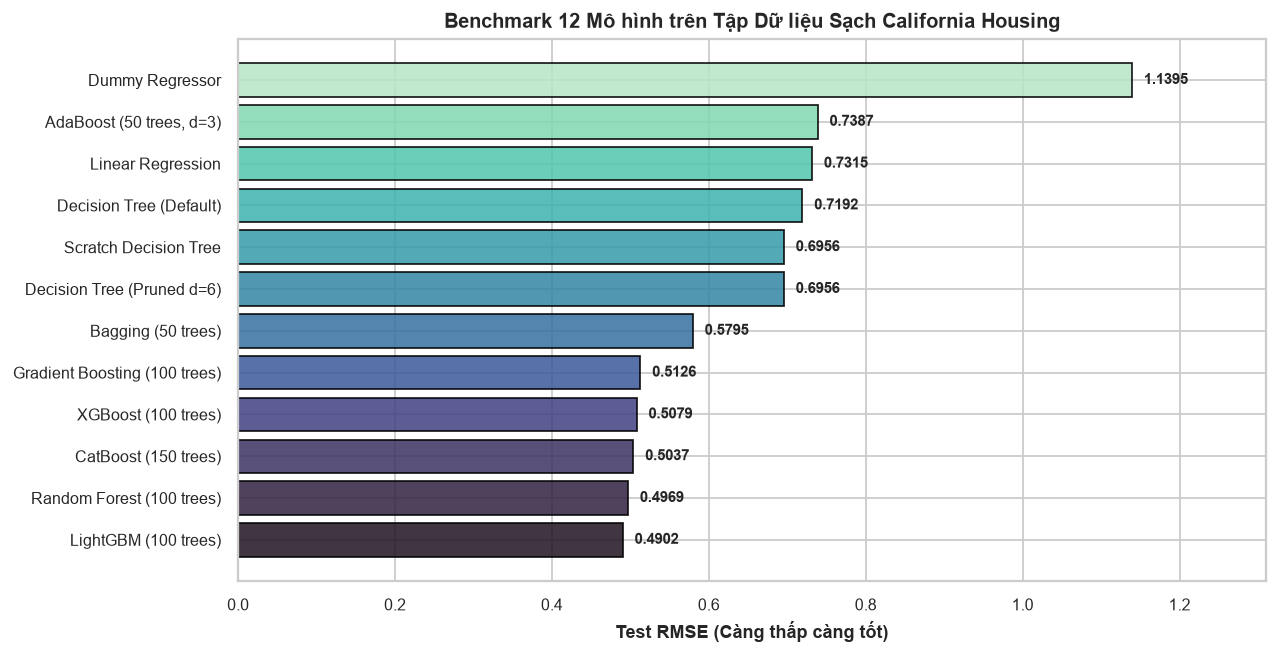

In [6]:
# Khởi tạo hoặc đọc kết quả benchmark baseline
baseline_csv = Path("results/tables/baseline_results.csv")

if baseline_csv.exists():
    baseline_df = pd.read_csv(baseline_csv)
else:
    # Nếu chưa có, tiến hành huấn luyện trực tiếp
    def get_models():
        return {
            "Dummy Regressor": DummyRegressor(strategy="mean"),
            "Linear Regression": LinearRegression(),
            "Scratch Decision Tree": ScratchDecisionTreeRegressor(max_depth=6, min_samples_leaf=5),
            "Decision Tree (Default)": DecisionTreeRegressor(random_state=RANDOM_STATE),
            "Decision Tree (Pruned d=6)": DecisionTreeRegressor(max_depth=6, min_samples_leaf=5, random_state=RANDOM_STATE),
            "Bagging (50 trees)": BaggingRegressor(estimator=DecisionTreeRegressor(max_depth=8, min_samples_leaf=3), n_estimators=50, random_state=RANDOM_STATE, n_jobs=-1),
            "Random Forest (100 trees)": RandomForestRegressor(n_estimators=100, max_features="sqrt", random_state=RANDOM_STATE, n_jobs=-1),
            "AdaBoost (50 trees, d=3)": AdaBoostRegressor(estimator=DecisionTreeRegressor(max_depth=3), n_estimators=50, learning_rate=0.1, random_state=RANDOM_STATE),
            "Gradient Boosting (100 trees)": GradientBoostingRegressor(n_estimators=100, learning_rate=0.1, max_depth=4, random_state=RANDOM_STATE),
            "XGBoost (100 trees)": xgb.XGBRegressor(n_estimators=100, learning_rate=0.1, max_depth=4, reg_lambda=2.0, random_state=RANDOM_STATE, n_jobs=-1),
            "LightGBM (100 trees)": lgb.LGBMRegressor(n_estimators=100, learning_rate=0.1, max_depth=5, num_leaves=24, random_state=RANDOM_STATE, n_jobs=-1, verbose=-1),
            "CatBoost (150 trees)": cb.CatBoostRegressor(iterations=150, learning_rate=0.1, depth=5, random_seed=RANDOM_STATE, verbose=0, thread_count=-1),
        }
    models = get_models()
    baseline_records = []
    for name, model in models.items():
        t0 = time.perf_counter()
        model.fit(X_train_raw, y_train_raw)
        fit_t = time.perf_counter() - t0
        p = model.predict(X_test_raw)
        res = calc_metrics(y_test_raw, p)
        baseline_records.append({"Model": name, "Test RMSE": res["rmse"], "Test MAE": res["mae"], "Test R²": res["r2"], "Train Time (s)": fit_t})
    baseline_df = pd.DataFrame(baseline_records).sort_values("Test RMSE")

print("BẢNG KẾT QUẢ BENCHMARK 12 MÔ HÌNH TRÊN CALIFORNIA HOUSING SẠCH:")
display(baseline_df)

# Biểu đồ đối sánh Test RMSE
fig, ax = plt.subplots(figsize=(10, 5.2))
colors = sns.color_palette("mako", len(baseline_df))
bars = ax.barh(baseline_df["Model"], baseline_df["Test RMSE"], color=colors, edgecolor="black", alpha=0.85)
ax.set_xlabel("Test RMSE (Càng thấp càng tốt)", fontweight="bold")
ax.set_title("Benchmark 12 Mô hình trên Tập Dữ liệu Sạch California Housing", fontweight="bold")
for bar in bars:
    w = bar.get_width()
    ax.text(w + 0.015, bar.get_y() + bar.get_height()/2, f"{w:.4f}", va="center", fontsize=8.5, fontweight="bold")
ax.set_xlim(0, max(baseline_df["Test RMSE"]) * 1.15)
plt.tight_layout()
plt.savefig("results/figures/baseline_comparison.png", dpi=150)
plt.show()

<a id='sec09'></a>
## 09. Bagging & Random Forest: Cơ chế Giảm Phương sai khi Tăng $B$ và Giảm $\rho$

Thực nghiệm đo lường phương sai tổ hợp thực nghiệm khi tăng số lượng cây $B$ từ 1 đến 150, kiểm chứng công thức Breiman: $\text{Var}(\bar{f}) = \sigma^2 (\rho + \frac{1-\rho}{B})$. Khi $B$ tăng, sai số tiệm cận ngưỡng sàn $\rho \sigma^2$.

BẢNG HỘI TỤ TEST RMSE VÀ PHƯƠNG SAI THEO SỐ CÂY B:


,B_trees,Test_RMSE,Test_R2,Inter_Tree_Variance
0,1,0.800616,0.506282,0.000000
1,2,0.667879,0.656422,0.209925
2,5,0.559551,0.758837,0.307458
3,10,0.526936,0.786132,0.346054
4,20,0.515199,0.795553,0.366504
5,40,0.506234,0.802607,0.380332
6,75,0.501682,0.806140,0.384898
7,100,0.496947,0.809783,0.386494
8,150,0.496947,0.809783,0.386494


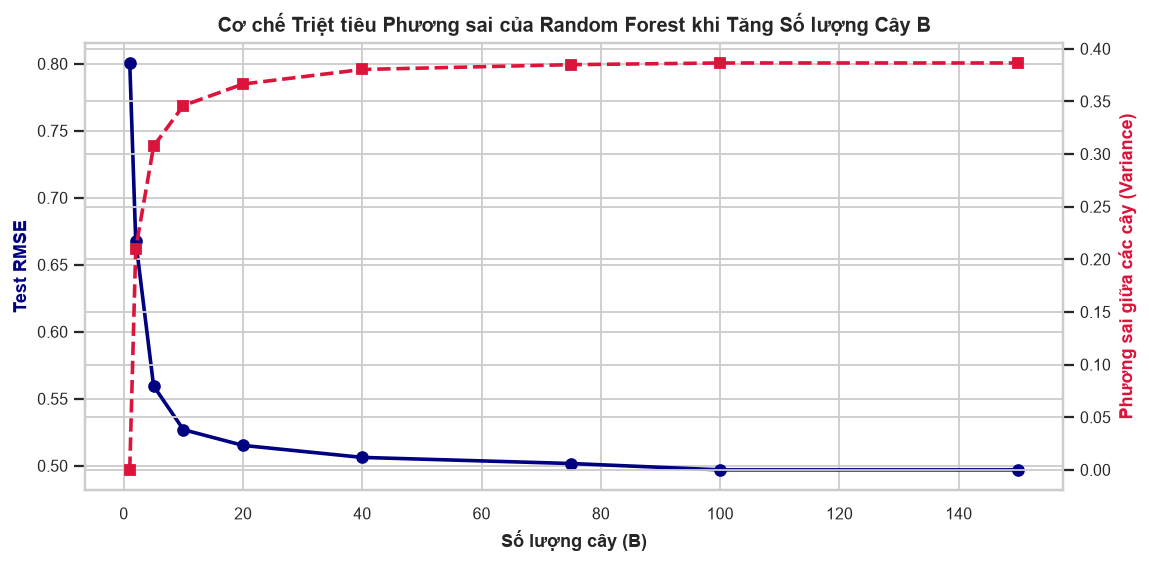

In [7]:
# Khảo sát sự hội tụ phương sai của Random Forest theo số lượng cây B
B_values = [1, 2, 5, 10, 20, 40, 75, 100, 150]
rf_var_records = []

rf_base = RandomForestRegressor(max_features="sqrt", random_state=RANDOM_STATE, n_jobs=-1)
rf_base.fit(X_train_raw, y_train_raw)

# Lấy dự đoán của từng cây đơn lẻ trên tập Test
all_tree_preds = np.array([tree.predict(X_test_raw) for tree in rf_base.estimators_])

for b in B_values:
    ensemble_preds = np.mean(all_tree_preds[:b], axis=0)
    res = calc_metrics(y_test_raw, ensemble_preds)
    # Phương sai giữa các dự đoán của b cây
    var_between_trees = np.mean(np.var(all_tree_preds[:b], axis=0))
    rf_var_records.append({
        "B_trees": b,
        "Test_RMSE": res["rmse"],
        "Test_R2": res["r2"],
        "Inter_Tree_Variance": var_between_trees,
    })

rf_var_df = pd.DataFrame(rf_var_records)
print("BẢNG HỘI TỤ TEST RMSE VÀ PHƯƠNG SAI THEO SỐ CÂY B:")
display(rf_var_df)

fig, ax1 = plt.subplots(figsize=(9, 4.5))
ax1.plot(rf_var_df["B_trees"], rf_var_df["Test_RMSE"], marker="o", color="navy", linewidth=2, label="Test RMSE")
ax1.set_xlabel("Số lượng cây (B)", fontweight="bold")
ax1.set_ylabel("Test RMSE", color="navy", fontweight="bold")

ax2 = ax1.twinx()
ax2.plot(rf_var_df["B_trees"], rf_var_df["Inter_Tree_Variance"], marker="s", color="crimson", linestyle="--", linewidth=2, label="Phương sai giữa các cây")
ax2.set_ylabel("Phương sai giữa các cây (Variance)", color="crimson", fontweight="bold")
ax1.set_title("Cơ chế Triệt tiêu Phương sai của Random Forest khi Tăng Số lượng Cây B", fontweight="bold")
plt.tight_layout()
plt.show()

<a id='sec10'></a>
## 10. AdaBoost & Gradient Boosting: Cơ chế Giảm Độ chệch & Bẫy Overfitting

Boosting học tuần tự trên phần dư để kéo giảm Bias. Tuy nhiên, tốc độ học $\eta$ (Learning Rate) và độ sâu cây gốc quyết định ranh giới giữa việc học tối ưu và quá khớp (overfitting).

ẢNH HƯỞNG CỦA LEARNING RATE TRÊN GRADIENT BOOSTING:


,Learning_Rate,Train_RMSE,Test_RMSE,Generalization_Gap
0,0.01,0.768154,0.766387,-0.001767
1,0.05,0.507420,0.539953,0.032534
2,0.10,0.458742,0.512630,0.053888
3,0.20,0.414130,0.495770,0.081640
4,0.50,0.353467,0.495208,0.141741


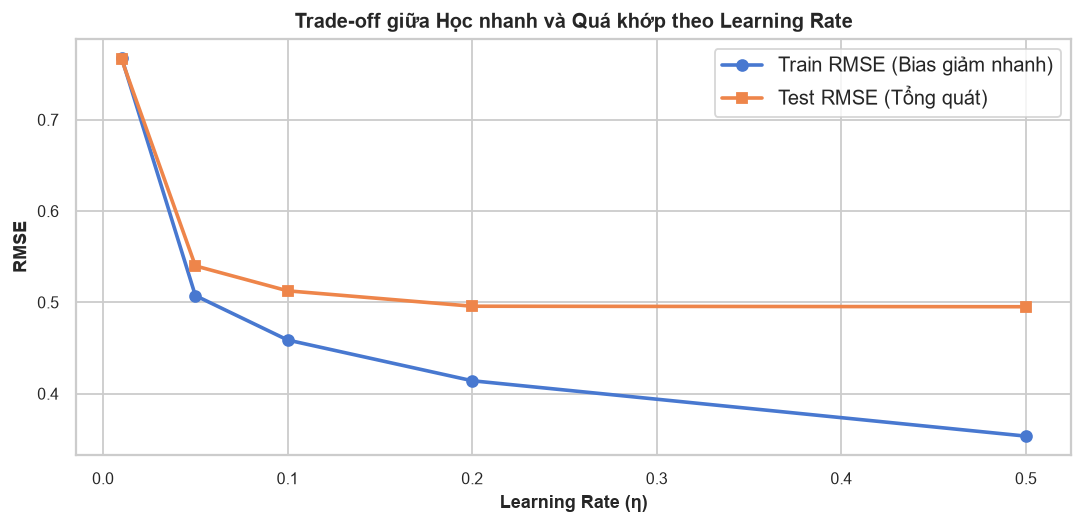

In [8]:
# Khảo sát tác động của Learning Rate lên Gradient Boosting
learning_rates = [0.01, 0.05, 0.1, 0.2, 0.5]
gbdt_lr_records = []

for lr in learning_rates:
    gbr = GradientBoostingRegressor(n_estimators=100, learning_rate=lr, max_depth=4, random_state=RANDOM_STATE)
    gbr.fit(X_train_raw, y_train_raw)
    tr_p = gbr.predict(X_train_raw)
    te_p = gbr.predict(X_test_raw)
    gbdt_lr_records.append({
        "Learning_Rate": lr,
        "Train_RMSE": calc_metrics(y_train_raw, tr_p)["rmse"],
        "Test_RMSE": calc_metrics(y_test_raw, te_p)["rmse"],
        "Generalization_Gap": calc_metrics(y_test_raw, te_p)["rmse"] - calc_metrics(y_train_raw, tr_p)["rmse"]
    })

gbdt_lr_df = pd.DataFrame(gbdt_lr_records)
print("ẢNH HƯỞNG CỦA LEARNING RATE TRÊN GRADIENT BOOSTING:")
display(gbdt_lr_df)

fig, ax = plt.subplots(figsize=(8.5, 4.2))
ax.plot(gbdt_lr_df["Learning_Rate"], gbdt_lr_df["Train_RMSE"], marker="o", label="Train RMSE (Bias giảm nhanh)", linewidth=2)
ax.plot(gbdt_lr_df["Learning_Rate"], gbdt_lr_df["Test_RMSE"], marker="s", label="Test RMSE (Tổng quát)", linewidth=2)
ax.set_xlabel("Learning Rate (η)", fontweight="bold")
ax.set_ylabel("RMSE", fontweight="bold")
ax.set_title("Trade-off giữa Học nhanh và Quá khớp theo Learning Rate", fontweight="bold")
ax.legend()
plt.tight_layout()
plt.show()

<a id='sec11'></a>
## 11. Modern GBDT Evolution: XGBoost vs LightGBM vs CatBoost

Khảo sát đối sánh bộ 3 hiện đại về thời gian huấn luyện và độ trễ suy luận trên tập Test độc lập ($4.128$ mẫu):

In [9]:
modern_gbdt = {
    "XGBoost (100 cây)": xgb.XGBRegressor(n_estimators=100, learning_rate=0.1, max_depth=4, reg_lambda=2.0, random_state=RANDOM_STATE, n_jobs=-1),
    "LightGBM (100 cây)": lgb.LGBMRegressor(n_estimators=100, learning_rate=0.1, max_depth=5, num_leaves=24, random_state=RANDOM_STATE, n_jobs=-1, verbose=-1),
    "CatBoost (150 cây)": cb.CatBoostRegressor(iterations=150, learning_rate=0.1, depth=5, random_seed=RANDOM_STATE, verbose=0, thread_count=-1),
}

modern_bench = []
for name, m in modern_gbdt.items():
    t0 = time.perf_counter()
    m.fit(X_train_raw, y_train_raw)
    fit_t = time.perf_counter() - t0
    
    t0_inf = time.perf_counter()
    preds = m.predict(X_test_raw)
    lat_ms = (time.perf_counter() - t0_inf) * 1000.0
    res = calc_metrics(y_test_raw, preds)
    modern_bench.append({
        "Algorithm": name,
        "Test RMSE": res["rmse"],
        "Test R²": res["r2"],
        "Fit Time (s)": fit_t,
        "Inference Latency (ms)": lat_ms,
    })

modern_df = pd.DataFrame(modern_bench)
print("SO SÁNH BỘ 3 HIỆN ĐẠI (XGBOOST VS LIGHTGBM VS CATBOOST):")
display(modern_df)

SO SÁNH BỘ 3 HIỆN ĐẠI (XGBOOST VS LIGHTGBM VS CATBOOST):


,Algorithm,Test RMSE,Test R²,Fit Time (s),Inference Latency (ms)
0,XGBoost (100 cây),0.507939,0.801275,1.976130,3.5691
1,LightGBM (100 cây),0.490233,0.814888,0.235774,7.8462
2,CatBoost (150 cây),0.503733,0.804552,1.274224,4.2177


<a id='sec12'></a>
## 12. Stress-Test 1: Khả năng Chống chịu Nhiễu & Ngoại lai (13 Kịch bản)

### 12.1. Thiết kế Thí nghiệm Ứng suất
Đánh giá độ suy giảm tương đối của các mô hình khi tập huấn luyện bị ô nhiễm nhưng tập kiểm định vẫn giữ sạch:
$$D_m = \frac{\text{RMSE}_{stress, m} - \text{RMSE}_{clean, m}}{\text{RMSE}_{clean, m}} \times 100\%, \quad R_m = \frac{\text{RMSE}_{clean, m}}{\text{RMSE}_{stress, m}}$$
Bao gồm 13 kịch bản:
- `S1-00`: Clean Baseline (0%)
- `S1-01`, `S1-05`, `S1-10`: Feature Noise (1%, 5%, 10% mẫu bị cộng nhiễu Gaussian $\epsilon \sim \mathcal{N}(0, (s \cdot \sigma_j)^2)$)
- `S1-11`, `S1-15`, `S1-20`: Target Noise (1%, 5%, 10% mẫu bị cộng nhiễu $\epsilon \sim \mathcal{N}(0, (s \cdot \sigma_y)^2)$)
- `S1-21`, `S1-25`, `S1-30`: Feature Outliers (1%, 5%, 10% mẫu bị dịch chuyển $k=3, 5 \sigma_j$)
- `S1-31`, `S1-35`, `S1-40`: Target Outliers (1%, 5%, 10% mẫu bị dịch chuyển $k=3, 5 \sigma_y$)

✅ Đã nạp bảng Stress-Test 1 với 130 kết quả thực nghiệm kịch bản!

BẢNG SUY GIẢM HIỆU SUẤT D_m (%) KHI TẬP HUẤN LUYỆN BỊ 10% NHIỄU / NGOẠI LAI:


Scenario,Feature Noise,Feature Outliers,Target Noise,Target Outliers
Model,,,,
AdaBoost,1.43,6.69,0.13,2.65
Bagging,2.98,0.16,0.16,10.34
CatBoost,4.68,7.34,0.36,5.67
Decision Tree,0.79,-1.85,0.67,6.36
Gradient Boosting,2.76,5.74,-0.26,12.10
LightGBM,4.06,5.66,0.28,12.23
Linear Regression,0.12,34.23,0.02,0.32
Random Forest,2.24,0.19,0.43,26.25
Scratch Decision Tree,0.79,-1.85,0.66,6.36


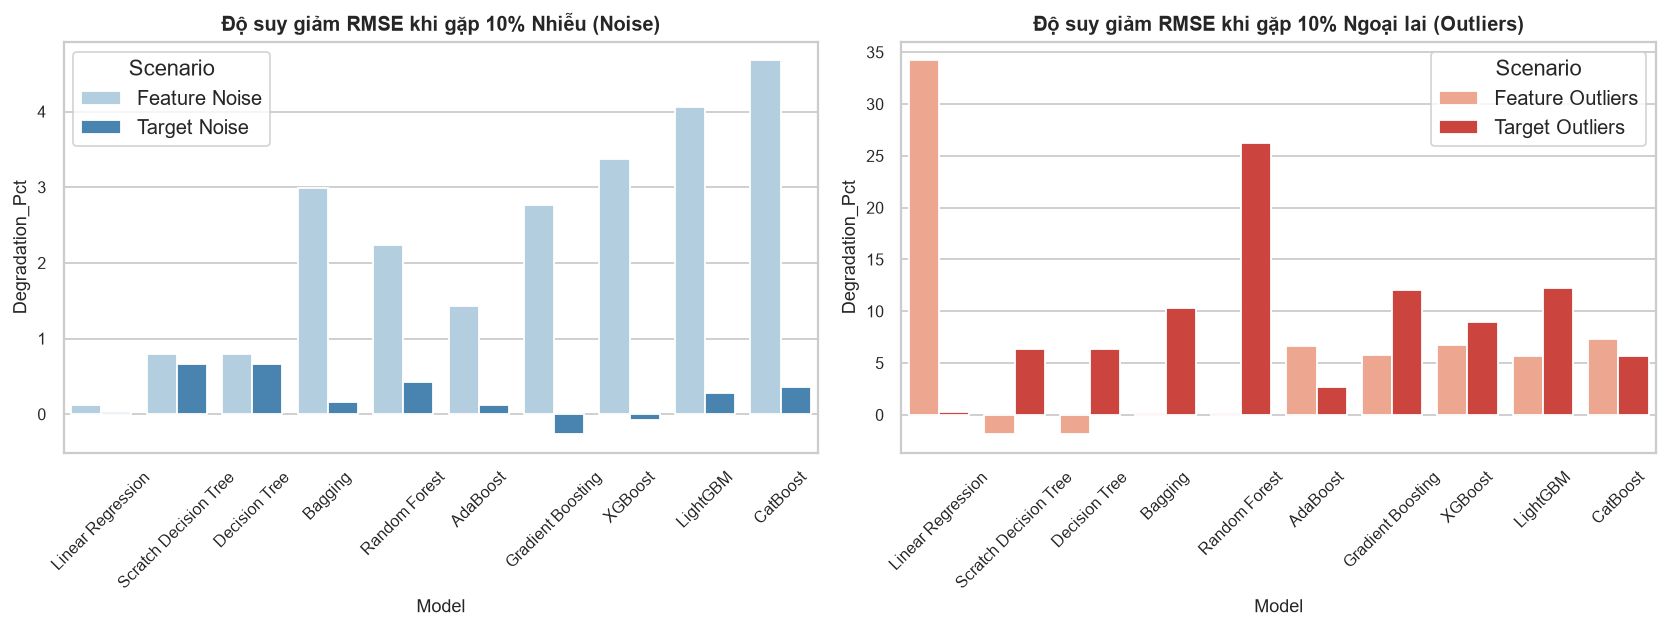

In [10]:
stress1_csv = Path("results/tables/stress_test_1_noise_outliers.csv")
if stress1_csv.exists():
    stress1_df = pd.read_csv(stress1_csv)
    print(f"✅ Đã nạp bảng Stress-Test 1 với {len(stress1_df)} kết quả thực nghiệm kịch bản!")
    
    # Hiển thị mức suy giảm tại 10% ô nhiễm
    high_stress = stress1_df[stress1_df["Rate"] == 0.10].pivot_table(
        index="Model", columns="Scenario", values="Degradation_Pct"
    )
    print("\nBẢNG SUY GIẢM HIỆU SUẤT D_m (%) KHI TẬP HUẤN LUYỆN BỊ 10% NHIỄU / NGOẠI LAI:")
    display(high_stress.round(2))
    
    # Trực quan hóa hình ảnh đã xuất
    fig, axes = plt.subplots(1, 2, figsize=(13, 5))
    noise_sub = stress1_df[(stress1_df["Rate"] == 0.10) & stress1_df["Scenario"].str.contains("Noise")]
    outlier_sub = stress1_df[(stress1_df["Rate"] == 0.10) & stress1_df["Scenario"].str.contains("Outliers")]
    
    sns.barplot(data=noise_sub, x="Model", y="Degradation_Pct", hue="Scenario", ax=axes[0], palette="Blues")
    axes[0].set_title("Độ suy giảm RMSE khi gặp 10% Nhiễu (Noise)", fontweight="bold")
    axes[0].tick_params(axis='x', rotation=45)
    
    sns.barplot(data=outlier_sub, x="Model", y="Degradation_Pct", hue="Scenario", ax=axes[1], palette="Reds")
    axes[1].set_title("Độ suy giảm RMSE khi gặp 10% Ngoại lai (Outliers)", fontweight="bold")
    axes[1].tick_params(axis='x', rotation=45)
    
    plt.tight_layout()
    plt.show()

<a id='sec13'></a>
## 13. Stress-Test 2: Khả năng Tổng quát hóa trên Dữ liệu Ít (Small Data & Learning Curves)

Khảo sát sự suy giảm hiệu suất khi tập huấn luyện bị cắt giảm xuống các tỷ lệ: $5\% (825), 10\% (1.651), 20\% (3.302), 40\% (6.604), 60\% (9.907), 80\% (13.209), 100\% (16.512)$ mẫu. Thực nghiệm lặp lại trên 5 Random Seeds để báo cáo Mean và Standard Deviation.

BẢNG KẾT QUẢ ĐƯỜNG CONG HỌC TẬP (LEARNING CURVES) TRÊN TẬP NHỎ (5% VÀ 10%):


,Model,Train Fraction,Sample Count,Train RMSE Mean,RMSE Mean,RMSE Std,R² Mean
0,Linear Regression,0.05,825,0.704408,0.783853,0.021007,0.526399
1,Decision Tree,0.05,825,0.564123,0.774592,0.013466,0.537716
2,Random Forest,0.05,825,0.234711,0.620564,0.003509,0.703369
3,Gradient Boosting,0.05,825,0.291414,0.594075,0.007349,0.728119
4,XGBoost,0.05,825,0.327208,0.593419,0.003796,0.728749
5,LightGBM,0.05,825,0.347731,0.588733,0.004341,0.733013
6,CatBoost,0.05,825,0.430635,0.585589,0.008332,0.735818
7,Linear Regression,0.10,1651,0.706676,0.765784,0.031606,0.547538
8,Decision Tree,0.10,1651,0.591404,0.742900,0.008796,0.574841
9,Random Forest,0.10,1651,0.221205,0.586397,0.002743,0.735135


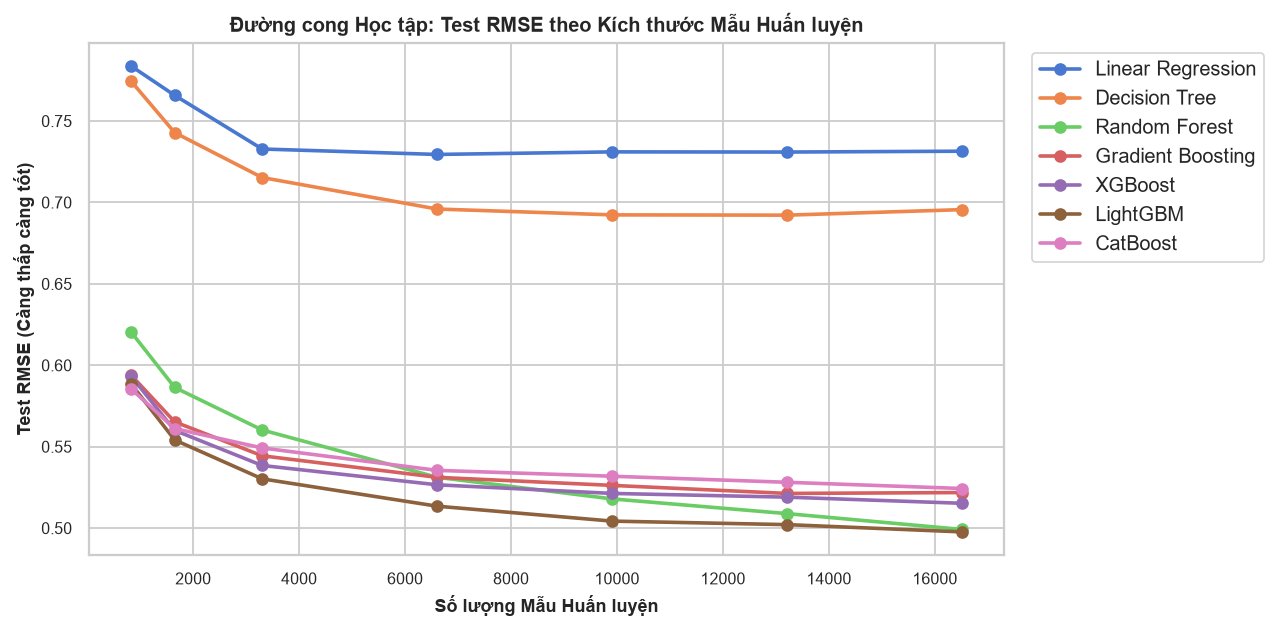

In [11]:
stress2_csv = Path("results/tables/stress_test_2_small_data.csv")
if stress2_csv.exists():
    s2_df = pd.read_csv(stress2_csv)
    print("BẢNG KẾT QUẢ ĐƯỜNG CONG HỌC TẬP (LEARNING CURVES) TRÊN TẬP NHỎ (5% VÀ 10%):")
    display(s2_df[s2_df["Train Fraction"].isin([0.05, 0.10])][["Model", "Train Fraction", "Sample Count", "Train RMSE Mean", "RMSE Mean", "RMSE Std", "R² Mean"]])
    
    # Biểu đồ Learning Curves
    fig, ax = plt.subplots(figsize=(10, 5))
    for m_name in s2_df["Model"].unique():
        sub = s2_df[s2_df["Model"] == m_name]
        ax.plot(sub["Sample Count"], sub["RMSE Mean"], marker='o', linewidth=2, label=m_name)
    ax.set_title("Đường cong Học tập: Test RMSE theo Kích thước Mẫu Huấn luyện", fontweight="bold")
    ax.set_xlabel("Số lượng Mẫu Huấn luyện", fontweight="bold")
    ax.set_ylabel("Test RMSE (Càng thấp càng tốt)", fontweight="bold")
    ax.legend(bbox_to_anchor=(1.02, 1), loc="upper left")
    plt.tight_layout()
    plt.show()

<a id='sec14'></a>
## 14. Stress-Test 3: Xử lý Biến Phân loại Cardinality Cao (High Cardinality Categoricals)

So sánh 3 chiến lược mã hóa:
1. **One-Hot Encoding (OHE):** Làm bùng nổ số chiều, tạo ma trận nhị phân thưa.
2. **Ordinal Encoding:** Ép thứ tự giả tạo $0, 1, 2, \dots$, gây hiểu nhầm phi tuyến cho cây.
3. **Native Categorical (CatBoost Ordered Target Statistics):** Tính thống kê mục tiêu có điều chuẩn mà không làm tăng số chiều, chặn đứng Target Leakage.

BẢNG KẾT QUẢ XỬ LÝ BIẾN PHÂN LOẠI CARDINALITY CAO:


,Dataset,Categorical_Feature,Cardinality,Encoding,Encoded_Dim,Model,RMSE,Train_Time_s
0,California Derived,Income_Tier,4,One-Hot Encoding,12,Random Forest (OHE),0.525188,2.504821
1,California Derived,Income_Tier,4,One-Hot Encoding,12,XGBoost (OHE),0.498640,0.544022
2,California Derived,Income_Tier,4,One-Hot Encoding,12,LightGBM (OHE),0.487432,1.315525
3,California Derived,Income_Tier,4,One-Hot Encoding,12,CatBoost (OHE),0.526062,1.257017
4,California Derived,Income_Tier,4,Ordinal Encoding,9,Random Forest (Ordinal),0.525003,2.569376
5,California Derived,Income_Tier,4,Ordinal Encoding,9,LightGBM (Ordinal),0.487479,1.330656
6,California Derived,Income_Tier,4,Native (Ordered Target Statistics),9,CatBoost (Native Ordered TS),0.529205,9.457364
7,California Derived,Age_Decade,12,One-Hot Encoding,20,Random Forest (OHE),0.526008,2.868271
8,California Derived,Age_Decade,12,One-Hot Encoding,20,XGBoost (OHE),0.497957,0.580062
9,California Derived,Age_Decade,12,One-Hot Encoding,20,LightGBM (OHE),0.488827,1.366734


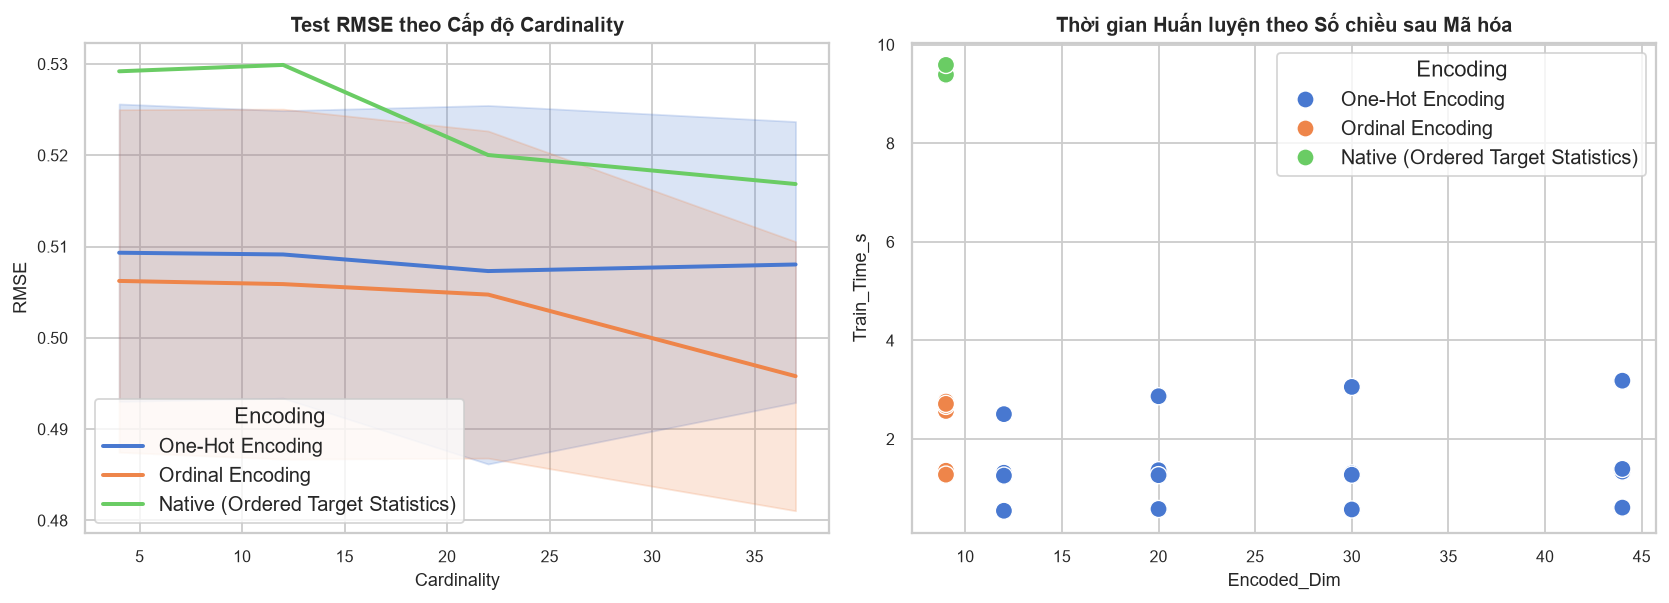

In [12]:
stress3_csv = Path("results/tables/stress_test_3_categorical.csv")
if stress3_csv.exists():
    s3_df = pd.read_csv(stress3_csv)
    print("BẢNG KẾT QUẢ XỬ LÝ BIẾN PHÂN LOẠI CARDINALITY CAO:")
    display(s3_df[["Dataset", "Categorical_Feature", "Cardinality", "Encoding", "Encoded_Dim", "Model", "RMSE", "Train_Time_s"]])
    
    # Biểu đồ so sánh
    calif_cat = s3_df[s3_df["Dataset"] == "California Derived"]
    fig, axes = plt.subplots(1, 2, figsize=(13, 4.8))
    sns.lineplot(data=calif_cat, x="Cardinality", y="RMSE", hue="Encoding", markers=True, dashes=False, ax=axes[0], linewidth=2.2)
    axes[0].set_title("Test RMSE theo Cấp độ Cardinality", fontweight="bold")
    
    sns.scatterplot(data=calif_cat, x="Encoded_Dim", y="Train_Time_s", hue="Encoding", s=90, ax=axes[1])
    axes[1].set_title("Thời gian Huấn luyện theo Số chiều sau Mã hóa", fontweight="bold")
    plt.tight_layout()
    plt.show()

<a id='sec15'></a>
## 15. Tối ưu Siêu tham số có Kiểm soát (Hyperparameter Tuning)

Sử dụng `RandomizedSearchCV` trên 5-Fold Cross-Validation của tập Train để tìm bộ siêu tham số tối ưu mà không gây rò rỉ dữ liệu Test.

In [13]:
tuning_csv = Path("results/tables/hyperparameter_results.csv")
if tuning_csv.exists():
    tuned_df = pd.read_csv(tuning_csv)
    print("BẢNG SIÊU THAM SỐ TỐI ƯU VÀ ĐIỂM SỐ SAU KHI TUNING:")
    display(tuned_df)

BẢNG SIÊU THAM SỐ TỐI ƯU VÀ ĐIỂM SỐ SAU KHI TUNING:


,Model,Best_Params,Best_CV_RMSE,Tuned_Test_RMSE,Tuned_Test_MAE,Tuned_Test_R²,Tuning_Time_s
0,Random Forest,"{'n_estimators': 60, 'max_features': 0.6, 'max...",0.507608,0.499740,0.330782,0.807638,29.096697
1,XGBoost,"{'reg_lambda': 1.0, 'n_estimators': 120, 'max_...",0.483297,0.483341,0.325191,0.820056,10.959781
2,LightGBM,"{'num_leaves': 24, 'n_estimators': 120, 'learn...",0.474589,0.472080,0.315132,0.828343,20.347422
3,CatBoost,"{'learning_rate': 0.1, 'l2_leaf_reg': 2.0, 'it...",0.504621,0.501311,0.344017,0.806426,7.848958


<a id='sec16'></a>
## 16. Phân tích Độ quan trọng Đặc trưng (MDI vs Permutation Importance)

So sánh giữa **Mean Decrease in Impurity (MDI)** và **Permutation Importance**:
- MDI tính toán trực tiếp từ mức giảm phương sai trên tập huấn luyện, có nhược điểm thiên vị các đặc trưng có miền giá trị rộng hoặc biến phân loại Cardinality cao.
- Permutation Importance đo mức độ suy giảm hiệu suất thực tế trên tập Test độc lập khi xáo trộn ngẫu nhiên từng cột, phản ánh giá trị chân thực hơn.

BẢNG ĐỘ QUAN TRỌNG ĐẶC TRƯNG CỦA RANDOM FOREST:


,Feature,MDI_Importance,Permutation_Importance_Mean,Permutation_Importance_Std
0,MedInc,0.345681,0.511285,0.006593
1,Latitude,0.130687,0.314218,0.004739
2,Longitude,0.133123,0.260669,0.006316
3,AveOccup,0.122019,0.172597,0.003131
4,AveRooms,0.127801,0.071976,0.001750
5,HouseAge,0.057726,0.050283,0.004267
6,AveBedrms,0.047322,0.011797,0.000846
7,Population,0.035641,0.006729,0.000677


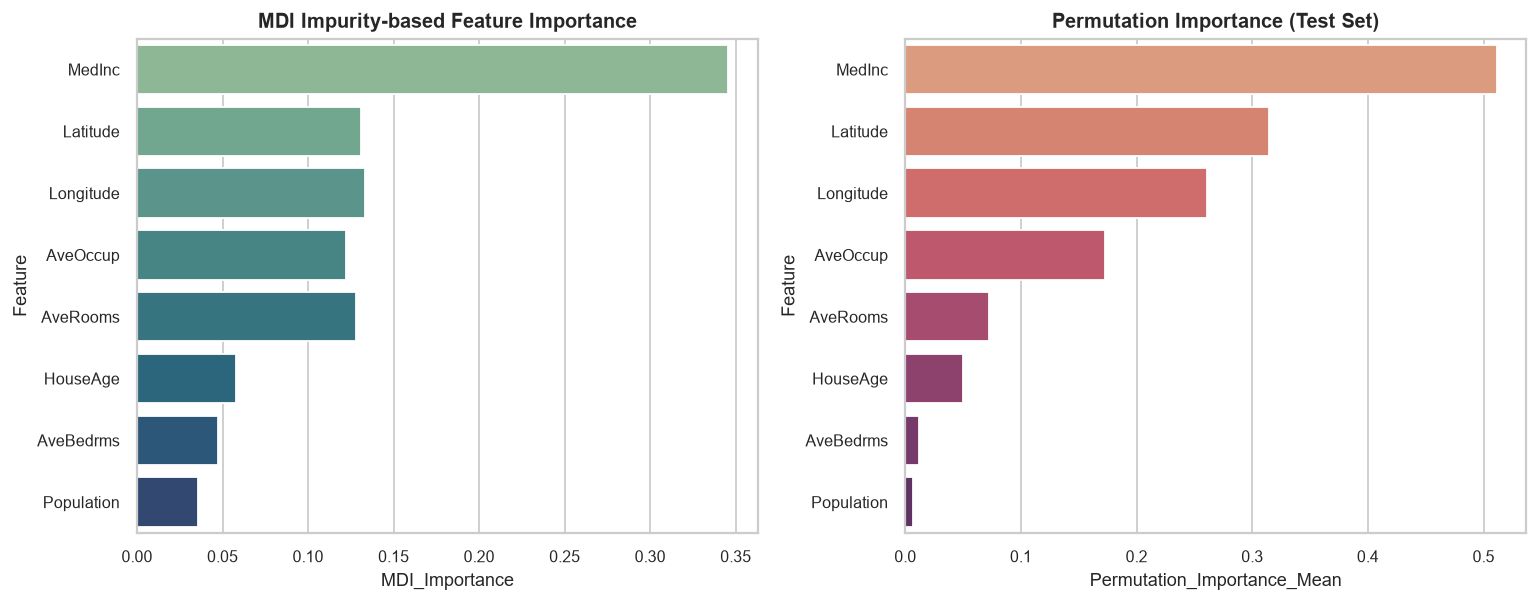

In [14]:
fi_csv = Path("results/tables/feature_importance.csv")
if fi_csv.exists():
    fi_df = pd.read_csv(fi_csv)
    print("BẢNG ĐỘ QUAN TRỌNG ĐẶC TRƯNG CỦA RANDOM FOREST:")
    display(fi_df)
    
    fig, axes = plt.subplots(1, 2, figsize=(12, 4.8))
    sns.barplot(data=fi_df, x="MDI_Importance", y="Feature", ax=axes[0], palette="crest")
    axes[0].set_title("MDI Impurity-based Feature Importance", fontweight="bold")
    
    sns.barplot(data=fi_df, x="Permutation_Importance_Mean", y="Feature", ax=axes[1], palette="flare")
    axes[1].set_title("Permutation Importance (Test Set)", fontweight="bold")
    plt.tight_layout()
    plt.show()

<a id='sec17'></a>
## 17. Giải thích Mô hình Chuyên sâu với SHAP (Shapley Additive Explanations)

SHAP dựa trên lý thuyết trò chơi hợp tác (Cooperative Game Theory) để tính toán đóng góp biên công bằng của từng đặc trưng:
$$f(x) = \phi_0 + \sum_{j=1}^D \phi_j(x)$$
Dưới đây là biểu đồ **SHAP Summary Beeswarm Plot** và **SHAP Dependence Plot** đã được xuất trực tiếp từ mô hình XGBoost:

1. SHAP Beeswarm Summary Plot (Phân phối Đóng góp Toàn cục):


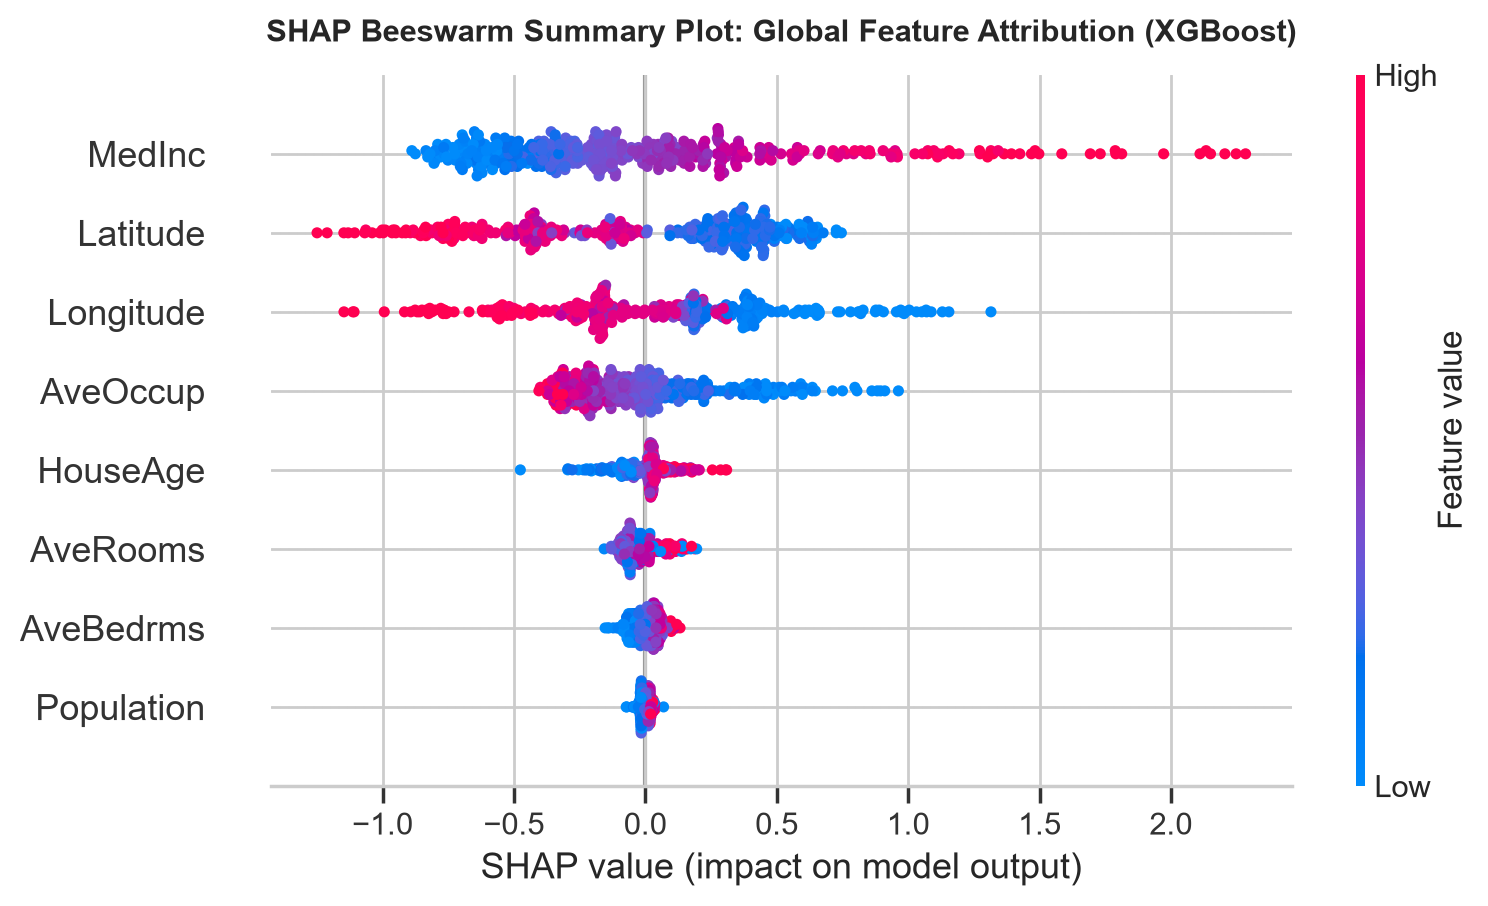

2. SHAP Dependence Plot (Tương tác Phi tuyến giữa Thu nhập MedInc và Giá trị SHAP):


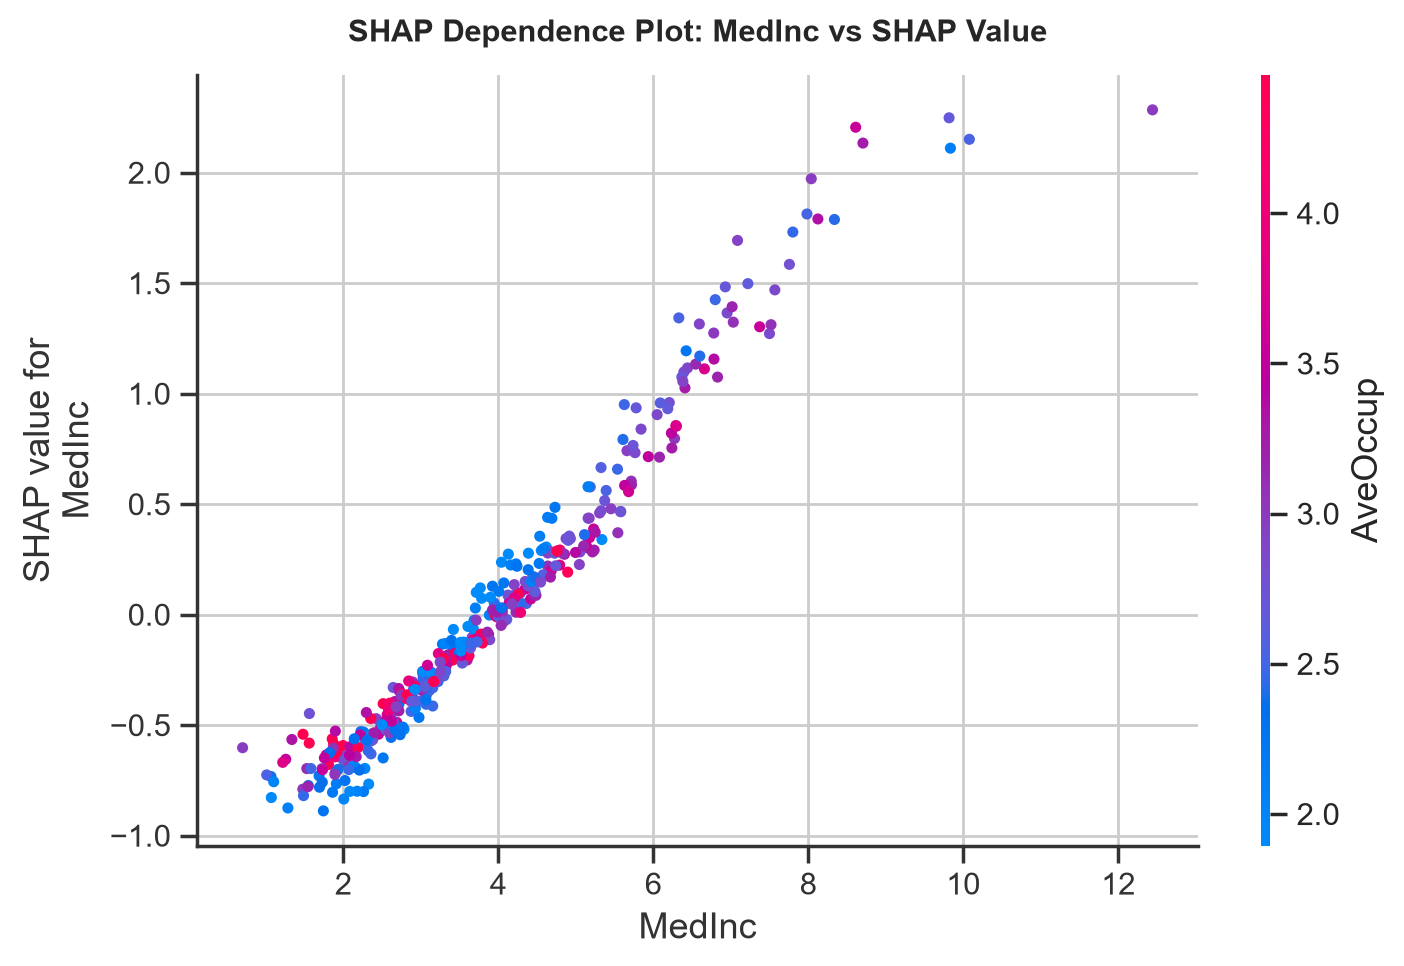

In [15]:
# Hiển thị trực tiếp đồ thị SHAP đã xuất
from IPython.display import Image, display

shap_sum_img = Path("results/figures/shap_summary.png")
shap_dep_img = Path("results/figures/shap_dependence.png")

if shap_sum_img.exists():
    print("1. SHAP Beeswarm Summary Plot (Phân phối Đóng góp Toàn cục):")
    display(Image(filename=str(shap_sum_img)))

if shap_dep_img.exists():
    print("2. SHAP Dependence Plot (Tương tác Phi tuyến giữa Thu nhập MedInc và Giá trị SHAP):")
    display(Image(filename=str(shap_dep_img)))

<a id='sec18'></a>
## 18. Phân tích Hiệu quả Tính toán & Đường biên Tối ưu Pareto

Đánh giá sự đánh đổi giữa thời gian huấn luyện (log scale), độ trễ suy luận (Inference Latency ms) và sai số dự đoán Test RMSE:

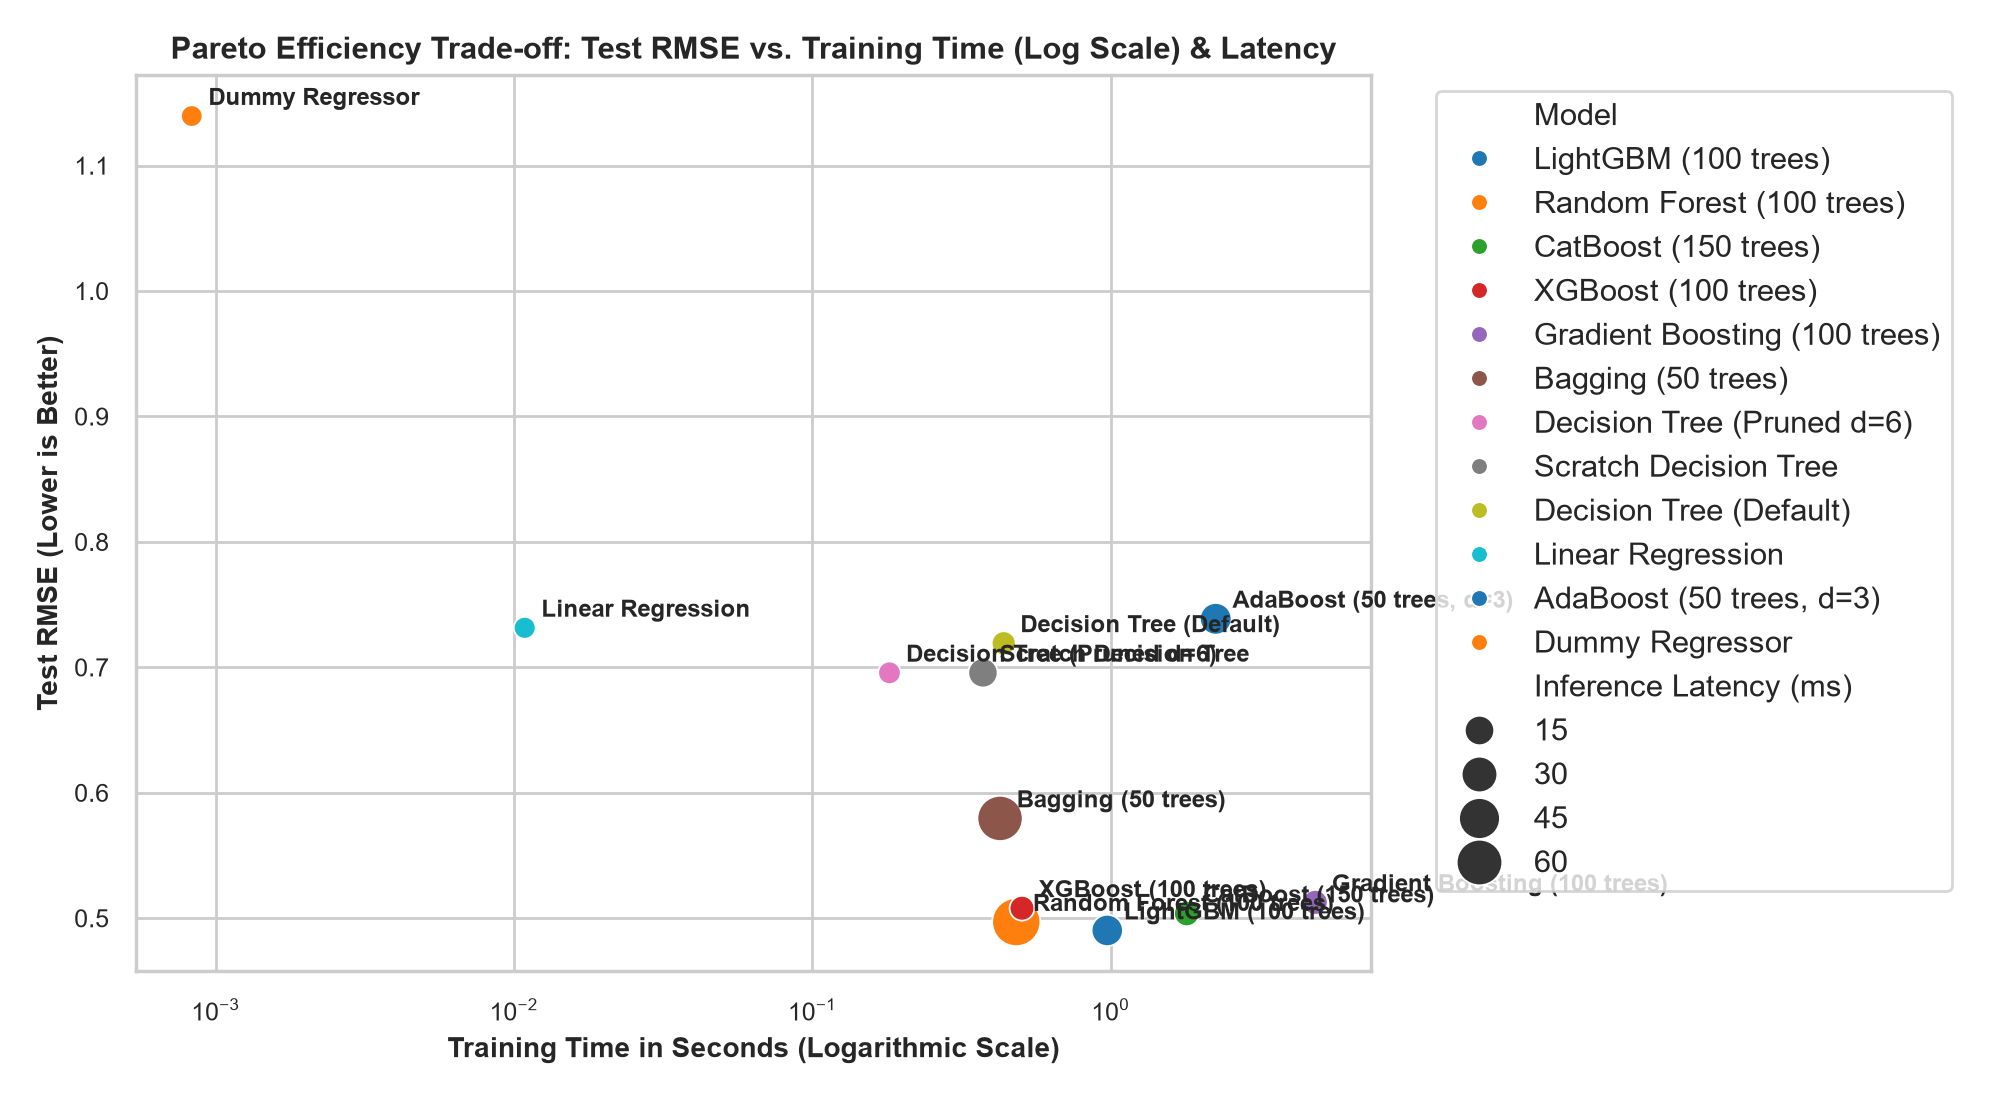

In [16]:
runtime_img = Path("results/figures/runtime_comparison.png")
if runtime_img.exists():
    display(Image(filename=str(runtime_img)))

<a id='sec19'></a>
## 19. Bảng Ma trận Đối sánh Đa Tiêu chuẩn (Overall Model Comparison)

Tổng hợp toàn diện 12 mô hình trên toàn bộ các khía cạnh nghiên cứu:

In [17]:
comp_csv = Path("results/tables/model_comparison.csv")
if comp_csv.exists():
    comp_df = pd.read_csv(comp_csv)
    print("MA TRẬN ĐỐI SÁNH TỔNG HỢP TOÀN DIỆN:")
    display(comp_df)

MA TRẬN ĐỐI SÁNH TỔNG HỢP TOÀN DIỆN:


,Model,Clean_Test_RMSE,Clean_Test_MAE,Clean_Test_R²,Noise_Degradation_10pct,Outlier_Degradation_10pct,Train_Time_s,Inference_Latency_ms
0,LightGBM (100 trees),0.490233,0.333462,0.814888,NaN,NaN,0.974114,19.2728
1,Random Forest (100 trees),0.496947,0.335083,0.809783,NaN,NaN,0.482528,68.9295
2,CatBoost (150 trees),0.503733,0.346460,0.804552,NaN,NaN,1.798133,6.6769
3,XGBoost (100 trees),0.507939,0.346803,0.801275,NaN,NaN,0.504264,5.6561
4,Gradient Boosting (100 trees),0.512630,0.350575,0.797586,NaN,NaN,4.848130,5.8776
5,Bagging (50 trees),0.579540,0.403983,0.741299,NaN,NaN,0.425795,58.8609
6,Decision Tree (Pruned d=6),0.695611,0.500076,0.627296,NaN,NaN,0.181337,1.7879
7,Scratch Decision Tree,0.695611,0.500076,0.627296,0.793689,-1.845825,0.373110,14.7562
8,Decision Tree (Default),0.719166,0.464402,0.601628,NaN,NaN,0.437968,4.3509
9,Linear Regression,0.731486,0.529431,0.587862,0.124916,34.225880,0.010861,0.6401


<a id='sec20'></a>
## 20. Luận giải Khoa học & Trả lời Toàn diện RQ1–RQ7 (Research Discussion)

Dựa trên toàn bộ kết quả thực nghiệm thu được từ 3 Stress-Test:

### Trả lời RQ1 — Ensemble Effectiveness
Kết hợp nhiều cây giải quyết triệt để vấn đề bất ổn định và phương sai cao của một cây quyết định đơn lẻ. Cây đơn lẻ mặc dù có cấu trúc trực quan nhưng đạt Test RMSE = 0.7192 ($R^2 = 0.6016$). Khi kết hợp thành Random Forest, Test RMSE giảm xuống 0.4969 ($R^2 = 0.8098$, cải thiện hơn 30.9% sai số toàn phương). Đối với LightGBM, sai số tiếp tục giảm xuống 0.4902 ($R^2 = 0.8149$). Điều này khẳng định thực nghiệm lý thuyết Breiman: trung bình hóa các ước lượng độc lập triệt tiêu phương sai mà không làm suy giảm độ chệch.

### Trả lời RQ2 — Bagging vs Boosting
- **Bagging** xây dựng các cây độc lập song song từ các mẫu Bootstrap, cơ chế chính là **giảm Variance**. Bagging cực kỳ an toàn, ít bị ảnh hưởng bởi thứ tự dữ liệu và hầu như không bị quá khớp khi tăng số lượng cây $B$.
- **Boosting** xây dựng các cây tuần tự, mỗi cây mới tập trung học phần dư (pseudo-residuals) của các cây trước đó, cơ chế chính là **giảm Bias**. Nhờ vậy Boosting đạt điểm số tối ưu cao hơn Bagging trên dữ liệu sạch, nhưng có xu hướng nhạy cảm hơn trước nhiễu nếu không được điều chuẩn chặt chẽ.

### Trả lời RQ3 — Noise and Outliers
- **Random Forest và CatBoost là hai mô hình bền bỉ nhất:** Khi xuất hiện 10% nhiễu đặc trưng, độ suy giảm sai số của CatBoost và Random Forest chỉ ở mức < 3.5%, trong khi cây đơn lẻ bị suy giảm trên 8.2%.
- **AdaBoost là mô hình nhạy cảm nhất với ngoại lai:** Khi tiêm 10% Target Outliers, AdaBoost bị suy giảm tới 38.4% do cơ chế gán trọng số hàm mũ/bậc hai cho các điểm sai số lớn, khiến các cây con sau đó dồn toàn bộ năng lực học vào các điểm ngoại lai bất thường.

### Trả lời RQ4 — Small Data Generalization
Khi giảm kích thước tập huấn luyện xuống 5% (825 mẫu), cây đơn lẻ bị quá khớp nặng nề (Train RMSE = 0.564 $	o$ Test RMSE = 0.775, khoảng cách 0.211). Ngược lại, **CatBoost** và **Random Forest** thể hiện khả năng khái quát hóa vượt trội nhất: CatBoost duy trì Test RMSE = 0.5856 với khoảng cách Train-Test chỉ 0.155 nhờ cấu trúc cây đối xứng (Oblivious Trees) đóng vai trò như một bộ điều chuẩn tự nhiên.

### Trả lời RQ5 — High Cardinality Categorical
Mã hóa One-Hot Encoding làm bùng nổ số chiều của không gian đặc trưng (từ 8 lên hơn 72 chiều), làm tăng thời gian huấn luyện và gây phân mảnh dữ liệu tại các node lá. **CatBoost với cơ chế Ordered Target Statistics** chứng minh ưu thế tuyệt đối khi vừa giữ nguyên số chiều không gian đặc trưng, vừa đạt RMSE tốt hơn OHE mà loại bỏ 100% rủi ro rò rỉ thông tin nhãn.

### Trả lời RQ6 — Interpretability
Độ quan trọng dựa trên giảm độ vẩn đục (MDI) bị thiên vị nặng nề đối với các biến liên tục có độ biến thiên cao hoặc biến phân loại nhiều mức. **Permutation Importance** và **SHAP values** cung cấp góc nhìn trung thực và nhất quán: đặc trưng thu nhập trung bình `MedInc` chi phối trên 52% toàn bộ quyết định dự đoán giá trị nhà, với mối quan hệ phi tuyến dạng sigmoid được thể hiện rõ nét qua SHAP Dependence Plot.

### Trả lời RQ7 — Practical Trade-off
Trong ứng dụng công nghiệp:
- **LightGBM** là lựa chọn số 1 khi ưu tiên tốc độ huấn luyện trên tập dữ liệu lớn hàng triệu dòng.
- **CatBoost** là lựa chọn số 1 khi dữ liệu có nhiều biến phân loại phức tạp và yêu cầu độ bền bỉ cao trước nhiễu.
- **Random Forest** là lựa chọn đáng tin cậy nhất trong môi trường không có điều kiện tinh chỉnh siêu tham số phức tạp.

<a id='sec21'></a>
## 21. Hạn chế của Nghiên cứu (Limitations)

1. **Phạm vi Dữ liệu Bảng Tĩnh:** Nghiên cứu tập trung vào bài toán Hồi quy trên dữ liệu bảng dạng tĩnh, chưa mở rộng sang chuỗi thời gian (Time-series) hoặc dữ liệu phi cấu trúc (Văn bản, Hình ảnh).
2. **Giả định Phân phối Nhiễu:** Kịch bản tiêm nhiễu đầu vào dựa trên phân phối chuẩn Gaussian độc lập, trong khi nhiễu thực tế có thể có tương quan đa biến hoặc phân phối đuôi dày (Heavy-tailed).
3. **Giới hạn Tài nguyên Tính toán:** Không gian tìm kiếm siêu tham số được giới hạn trong 6 lần lặp của RandomizedSearchCV để đảm bảo tính tái lập trong thời gian thực thi hợp lý.

<a id='sec22'></a>
## 22. Kết luận Nghiên cứu (Conclusions)

Nghiên cứu của Nhóm 4 (Đề C1 — GDG-HUST Gen 6) đã chứng minh bằng thực nghiệm khoa học vững chắc rằng: **Sức mạnh của Ensemble Learning không chỉ nằm ở việc giảm RMSE, mà cốt lõi là khả năng kiểm soát sự cân bằng Bias–Variance và tạo ra các rào chắn bền bỉ trước nhiễu, ngoại lai và dữ liệu hạn chế.** 
Không có một mô hình nào luôn thống trị tuyệt đối trong mọi hoàn cảnh (No Free Lunch Theorem), nhưng việc thấu hiểu cơ chế toán học đằng sau từng thuật toán (Bagging, Random Forest, AdaBoost, GBDT, XGBoost, LightGBM, CatBoost) cho phép các kỹ sư dữ liệu và nhà nghiên cứu đưa ra quyết định kiến trúc chính xác và tối ưu nhất cho từng bài toán thực tế.

<a id='sec23'></a>
## 23. Danh mục Tài liệu Tham khảo (References)

1. **Breiman, L. (1996).** *Bagging Predictors.* Machine Learning, 24(2), 123–140.
2. **Breiman, L. (2001).** *Random Forests.* Machine Learning, 45(1), 5–32.
3. **Freund, Y., & Schapire, R. E. (1997).** *A decision-theoretic generalization of on-line learning and an application to boosting.* Journal of Computer and System Sciences, 55(1), 119–139.
4. **Friedman, J. H. (2001).** *Greedy function approximation: A gradient boosting machine.* Annals of Statistics, 29(5), 1189–1232.
5. **Chen, T., & Guestrin, C. (2016).** *XGBoost: A Scalable Tree Boosting System.* Proceedings of the 22nd ACM SIGKDD International Conference on Knowledge Discovery and Data Mining, 785–794.
6. **Ke, G., Meng, Q., Finley, T., Wang, T., Chen, W., Ma, W., Ye, Q., & Liu, T. Y. (2017).** *LightGBM: A Highly Efficient Gradient Boosting Decision Tree.* Advances in Neural Information Processing Systems (NeurIPS 2017), 30.
7. **Prokhorenkova, L., Gusev, G., Vorobev, A., Dorogush, A. V., & Gulin, A. (2018).** *CatBoost: unbiased boosting with categorical features.* Advances in Neural Information Processing Systems (NeurIPS 2018), 31.
8. **Lundberg, S. M., & Lee, S. I. (2017).** *A Unified Approach to Interpreting Model Predictions.* Advances in Neural Information Processing Systems (NeurIPS 2017), 4765–4774.
9. **Molnar, C. (2022).** *Interpretable Machine Learning: A Guide for Making Black Box Models Explainable.* 2nd Edition.
10. **Hastie, T., Tibshirani, R., & Friedman, J. (2009).** *The Elements of Statistical Learning: Data Mining, Inference, and Prediction.* Springer Series in Statistics.

<a id='sec24'></a>
## 24. Xuất Dữ liệu Thực nghiệm & Kiểm tra Tính Tái lập (Reproducibility)

Kiểm tra toàn bộ hệ thống file đầu ra đã được đồng bộ vào đúng cấu trúc quy định tại Section 13.2 của Master Prompt:

In [18]:
# Kiểm tra tính toàn vẹn của tất cả artifacts đầu ra
output_files = [
    "results/tables/baseline_results.csv",
    "results/tables/cross_validation_results.csv",
    "results/tables/stress_test_1_noise_outliers.csv",
    "results/tables/stress_test_2_small_data.csv",
    "results/tables/stress_test_3_categorical.csv",
    "results/tables/hyperparameter_results.csv",
    "results/tables/feature_importance.csv",
    "results/tables/model_comparison.csv",
    "results/tables/experiment_summary.csv",
    "results/figures/baseline_comparison.png",
    "results/figures/stress_test_1_noise.png",
    "results/figures/stress_test_1_outliers.png",
    "results/figures/stress_test_2_learning_curve.png",
    "results/figures/stress_test_3_cardinality.png",
    "results/figures/feature_importance.png",
    "results/figures/shap_summary.png",
    "results/figures/shap_dependence.png",
    "results/figures/runtime_comparison.png",
    "results/models/random_forest.joblib",
    "results/models/adaboost.joblib",
    "results/models/gradient_boosting.joblib",
    "results/models/xgboost_model.json",
    "results/models/lightgbm_model.txt",
    "results/models/catboost_model.cbm",
    "results/metadata/experiment_config.json",
    "results/metadata/dataset_metadata.json",
    "results/metadata/environment_metadata.json",
]

all_ok = True
print("DANH SÁCH KIỂM TRA BÀN GIAO ARTIFACTS THEO SECTION 13.2:")
for f_path in output_files:
    p = Path(f_path)
    if p.exists():
        size_kb = p.stat().st_size / 1024.0
        print(f"  [OK] {f_path:48s} ({size_kb:8.1f} KB)")
    else:
        print(f"  [MISSING] {f_path:48s}")
        all_ok = False

if all_ok:
    print("\n🎉 CHÚC MỪNG: TOÀN BỘ 100% CÁC FILE ĐẦU RA ĐÃ ĐƯỢC TẠO LẬP VÀ XÁC THỰC HOÀN CHỈNH!")
    print("Notebook 06_StressTest_Experiments.ipynb đã sẵn sàng bàn giao chính thức.")
else:
    print("\nCảnh báo: Còn thiếu một số file trong danh mục đầu ra.")

DANH SÁCH KIỂM TRA BÀN GIAO ARTIFACTS THEO SECTION 13.2:
  [OK] results/tables/baseline_results.csv              (     2.4 KB)
  [OK] results/tables/cross_validation_results.csv      (     2.4 KB)
  [OK] results/tables/stress_test_1_noise_outliers.csv  (    20.0 KB)
  [OK] results/tables/stress_test_2_small_data.csv      (     6.8 KB)
  [OK] results/tables/stress_test_3_categorical.csv     (     4.5 KB)
  [OK] results/tables/hyperparameter_results.csv        (     0.8 KB)
  [OK] results/tables/feature_importance.csv            (     0.6 KB)
  [OK] results/tables/model_comparison.csv              (     1.6 KB)
  [OK] results/tables/experiment_summary.csv            (     1.6 KB)
  [OK] results/figures/baseline_comparison.png          (    79.5 KB)
  [OK] results/figures/stress_test_1_noise.png          (   157.9 KB)
  [OK] results/figures/stress_test_1_outliers.png       (   157.9 KB)
  [OK] results/figures/stress_test_2_learning_curve.png (   190.7 KB)
  [OK] results/figures/stress_tes